# Задание 5-6. SVM, kNN и Random Forest — вариант 4 (`pen_digits`)

| Параметр | Значение |
|---|---|
| Набор данных | `pen_digits` (из `imblearn.datasets.fetch_datasets`) |
| Объектов / признаков | 10 992 / 16 |
| Соотношение классов | ≈ 9.4 : 1 (цифра «5» против остальных цифр) |
| Столбец с меткой | `Target` |

**Содержание**
* **Часть A** — SVM: ядра linear / RBF / poly / sigmoid, grid search по `C` и параметрам ядра, число опорных векторов, визуализация t-SNE / UMAP / TriMap / PaCMAP с выделением опорных векторов.
* **Часть B** — kNN: grid search по числу соседей, метрикам расстояния и правилам голосования, визуализация.
* **Часть C** — Random Forest: grid search, сравнение правил голосования (soft / hard), визуализация, разбор двух деревьев леса.

**Как запускать:** в Colab — `Среда выполнения → Выполнить все`. Самая долгая часть — grid search. На 2 ядрах весь ноутбук выполнялся ≈ 7 минут, в бесплатном Colab рассчитывайте на 7–12 минут.

**Ресурсы.** Ноутбук рассчитан на бесплатный Colab (2 vCPU, ~12 ГБ ОЗУ) и на ноутбук с Intel Core Ultra 5 125U / 32 ГБ:
* grid search для SVM идёт на стратифицированной подвыборке обучающего множества (`SVM_GS_SIZE` объектов), а лучшие модели затем переобучаются на всём train;
* t-SNE / UMAP / TriMap / PaCMAP строятся на подвыборке (`VIZ_TRAIN_SIZE + VIZ_TEST_SIZE` объектов);
* для RF используется 3-кратная кросс-валидация и небольшая сетка.

Все эти размеры задаются в ячейке «Настройки». Если ресурсов больше, их можно увеличить.

> **Примечания к формулировке задания.**
> 1. В частях B и C указан «набор данных из варианта для задания 1». Здесь использован тот же набор `pen_digits`. Если для задания 1 у вас другой набор, поменяйте `DATASET_NAME` (подойдёт любой набор из `fetch_datasets`).
> 2. В части C текст для RF скопирован из части B («число соседей, метрики расстояний»). У случайного леса таких параметров нет, поэтому перебираются их аналоги: число деревьев, глубина, критерий разбиения, число признаков при разбиении, размер листа и веса классов. Правила голосования (soft / hard) сравниваются отдельно.

In [ ]:
# Установка библиотек для понижения размерности (в Colab umap/imblearn обычно уже есть)
!pip install -q umap-learn trimap pacmap imbalanced-learn

In [1]:
import os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import plot_tree, export_text
from sklearn.manifold import TSNE
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, ConfusionMatrixDisplay)
from imblearn.datasets import fetch_datasets

import umap, trimap, pacmap

warnings.filterwarnings('ignore')
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 30)
plt.rcParams['figure.dpi'] = 90
print('CPU ядер доступно:', os.cpu_count())

CPU ядер доступно: 4


## Настройки

In [2]:
DATASET_NAME   = 'pen_digits'
RANDOM_STATE   = 42
N_JOBS         = -1     # все ядра (в Colab 2, на Core Ultra 5 125U — 14 потоков)
TEST_SIZE      = 0.25
CV_FOLDS       = 5      # для SVM и kNN
RF_CV_FOLDS    = 3      # для RF (каждая модель дороже)

SVM_GS_SIZE    = 3000   # размер подвыборки train для grid search SVM
VIZ_TRAIN_SIZE = 1500   # train-объектов в визуализации (сюда входят опорные векторы)
VIZ_TEST_SIZE  = 1000   # test-объектов в визуализации
MAX_SV_IN_VIZ  = 1000   # максимум опорных векторов на рисунках

np.random.seed(RANDOM_STATE)
CLASS_NAMES = ['0: не «5»', '1: цифра «5»']

## 1. Загрузка и первичный анализ данных

В `imblearn` метки классов `pen_digits` имеют вид −1 / +1 (+1 — цифра «5»). Для удобства переводим их в 0 / 1: **1 — миноритарный (положительный) класс**. Precision, Recall и F1 считаются для класса 1.

Признаки описывают траекторию пера: 8 точек `(x_i, y_i)`, нормированных на диапазон 0…100.

In [3]:
try:
    ds = fetch_datasets(filter_data=(DATASET_NAME,), verbose=True)[DATASET_NAME]
    X_raw, y_raw = ds.data, ds.target
except Exception as e:   # запасной вариант, если зеркало imblearn недоступно
    print('fetch_datasets не сработал:', e, '\n-> загружаю pendigits с OpenML')
    from sklearn.datasets import fetch_openml
    assert DATASET_NAME == 'pen_digits', 'запасной вариант есть только для pen_digits'
    oml = fetch_openml('pendigits', version=1, as_frame=False)
    X_raw, y_raw = oml.data, np.where(oml.target.astype(int) == 5, 1, -1)

X = np.asarray(X_raw, dtype=float)
y = (np.asarray(y_raw) == 1).astype(int)

n_feat = X.shape[1]
FEATURE_NAMES = ([f'{c}{i}' for i in range(1, n_feat // 2 + 1) for c in ('x', 'y')]
                 if DATASET_NAME == 'pen_digits' else [f'f{i}' for i in range(n_feat)])
df = pd.DataFrame(X, columns=FEATURE_NAMES)
df['Target'] = y

print('Размер:', X.shape)
counts = pd.Series(y).value_counts().sort_index()
print(counts.rename(index=dict(enumerate(CLASS_NAMES))))
print(f'Дисбаланс: {counts[0] / counts[1]:.2f} : 1')
df.describe().T.round(2)

Размер: (10992, 16)
0: не «5»       9937
1: цифра «5»    1055
Name: count, dtype: int64
Дисбаланс: 9.42 : 1


,count,mean,std,min,25%,50%,75%,max
x1,10992.0,38.81,34.26,0.0,6.0,32.0,65.0,100.0
y1,10992.0,85.12,16.22,0.0,76.0,89.0,100.0,100.0
x2,10992.0,40.61,26.34,0.0,20.0,40.0,58.0,100.0
y2,10992.0,83.77,19.16,0.0,72.0,91.0,100.0,100.0
x3,10992.0,49.77,34.10,0.0,18.0,53.0,78.0,100.0
y3,10992.0,65.57,27.00,0.0,49.0,71.0,86.0,100.0
x4,10992.0,51.22,30.58,0.0,28.0,53.5,74.0,100.0
y4,10992.0,44.50,29.91,0.0,23.0,43.0,64.0,100.0
x5,10992.0,56.87,34.14,0.0,29.0,60.0,89.0,100.0
y5,10992.0,33.70,27.25,0.0,7.0,33.0,54.0,100.0


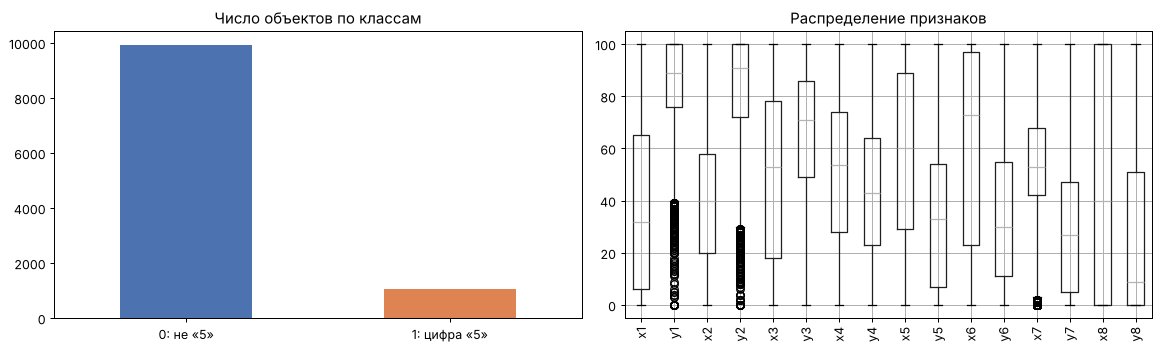

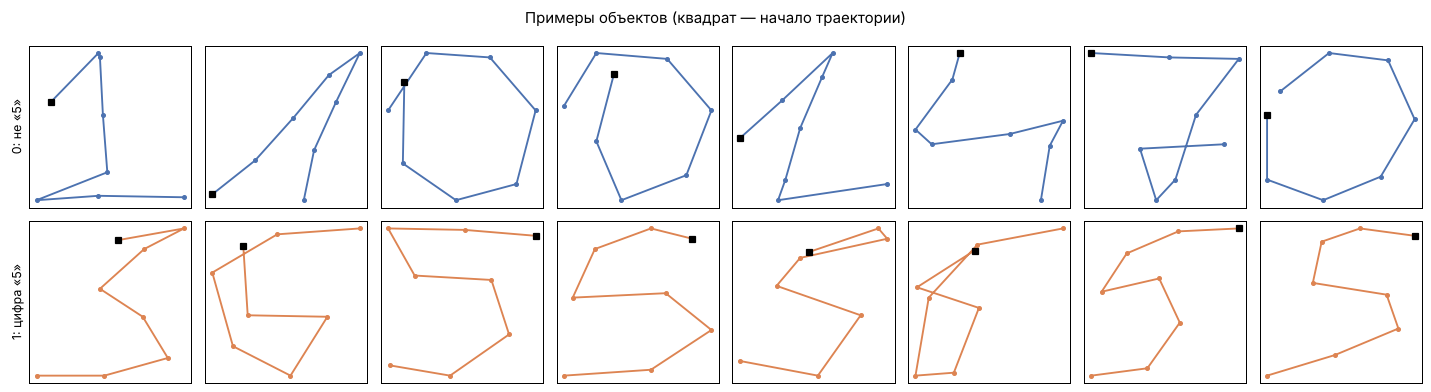

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
counts.rename(index=dict(enumerate(CLASS_NAMES))).plot.bar(ax=axes[0], color=['#4C72B0', '#DD8452'], rot=0)
axes[0].set_title('Число объектов по классам')
df.drop(columns='Target').boxplot(ax=axes[1], rot=90)
axes[1].set_title('Распределение признаков')
plt.tight_layout(); plt.show()

if DATASET_NAME == 'pen_digits':
    # Каждая строка — 8 точек траектории пера. Нарисуем несколько примеров каждого класса
    fig, axes = plt.subplots(2, 8, figsize=(16, 4.4))
    for row, cls in enumerate([0, 1]):
        for ax, i in zip(axes[row], np.random.choice(np.where(y == cls)[0], 8, replace=False)):
            ax.plot(X[i, 0::2], X[i, 1::2], '-o', ms=3, color=['#4C72B0', '#DD8452'][cls])
            ax.plot(X[i, 0], X[i, 1], 'ks', ms=5)   # начало штриха
            ax.set_xlim(-5, 105); ax.set_ylim(-5, 105); ax.set_xticks([]); ax.set_yticks([])
        axes[row, 0].set_ylabel(CLASS_NAMES[cls])
    plt.suptitle('Примеры объектов (квадрат — начало траектории)'); plt.tight_layout(); plt.show()

### Разбиение на обучающую и тестовую выборки
Разбиение **стратифицированное**, чтобы доля миноритарного класса в train и test была одинаковой. Масштабирование (`StandardScaler`) для SVM и kNN выполняется внутри `Pipeline`, поэтому при кросс-валидации оно обучается только на обучающих фолдах.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE)
print('train:', X_train.shape, ' доля класса 1 = %.3f' % y_train.mean())
print('test :', X_test.shape,  ' доля класса 1 = %.3f' % y_test.mean())

train: (8244, 16)  доля класса 1 = 0.096
test : (2748, 16)  доля класса 1 = 0.096


### Вспомогательные функции
* `evaluate` считает accuracy, precision, recall и F1 на train и test;
* `show_confusion` рисует матрицы ошибок;
* `compute_embeddings` строит 2D-вложения t-SNE / UMAP / TriMap / PaCMAP при нескольких наборах параметров;
* `plot_embeddings` рисует истинные и предсказанные классы, ошибки и опорные векторы.

Из-за дисбаланса классов **accuracy малоинформативна**: модель, которая всегда отвечает «0», получает ≈ 0.904. Поэтому модели выбираются по **F1 для класса 1**.

In [6]:
def metrics_row(y_true, y_pred):
    return dict(accuracy=accuracy_score(y_true, y_pred),
                precision=precision_score(y_true, y_pred, zero_division=0),
                recall=recall_score(y_true, y_pred, zero_division=0),
                f1=f1_score(y_true, y_pred, zero_division=0))


def evaluate(model, name):
    rows = []
    for part, Xp, yp in [('train', X_train, y_train), ('test', X_test, y_test)]:
        rows.append(dict(model=name, sample=part, **metrics_row(yp, model.predict(Xp))))
    return pd.DataFrame(rows).set_index(['model', 'sample']).round(4)


def show_confusion(model, name):
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    for ax, (part, Xp, yp) in zip(axes, [('train', X_train, y_train), ('test', X_test, y_test)]):
        ConfusionMatrixDisplay.from_predictions(yp, model.predict(Xp), display_labels=CLASS_NAMES,
                                                ax=ax, cmap='Blues', colorbar=False)
        ax.set_title(f'{name}: {part}')
    plt.tight_layout(); plt.show()
    print(f'Classification report ({name}, test):')
    print(classification_report(y_test, model.predict(X_test), target_names=CLASS_NAMES, digits=4))


def cv_table(gs, params, top=None):
    # Таблица результатов GridSearchCV
    res = pd.DataFrame(gs.cv_results_)
    cols = ['param_' + p for p in params]
    metric_cols = ([c for c in res.columns if c.startswith('mean_test_')]
                   + [c for c in ['mean_train_f1', 'mean_fit_time'] if c in res])
    out = res[cols + metric_cols].copy()
    out.columns = [c.replace('param_', '').split('__')[-1] for c in out.columns]
    for c in ['class_weight', 'max_depth']:   # значение None в cv_results_ превращается в NaN
        if c in out:
            out[c] = out[c].astype(object).where(out[c].notna(), 'None')
    out = out.sort_values('mean_test_f1', ascending=False, kind='stable')
    return (out.head(top) if top else out).round(4)

In [7]:
# Наборы параметров методов понижения размерности
EMBED_CONFIGS = {
    't-SNE':  [dict(perplexity=10), dict(perplexity=30), dict(perplexity=50)],
    'UMAP':   [dict(n_neighbors=5,  min_dist=0.05), dict(n_neighbors=15, min_dist=0.1),
               dict(n_neighbors=50, min_dist=0.5)],
    'TriMap': [dict(n_inliers=5,  n_outliers=3, n_random=1), dict(n_inliers=12, n_outliers=4, n_random=3),
               dict(n_inliers=25, n_outliers=8, n_random=5)],
    'PaCMAP': [dict(n_neighbors=5,  MN_ratio=0.5, FP_ratio=2.0), dict(n_neighbors=10, MN_ratio=0.5, FP_ratio=2.0),
               dict(n_neighbors=30, MN_ratio=1.0, FP_ratio=4.0)],
}


def make_reducer(method, params):
    if method == 't-SNE':
        return TSNE(n_components=2, init='pca', random_state=RANDOM_STATE, n_jobs=N_JOBS, **params)
    if method == 'UMAP':
        return umap.UMAP(n_components=2, random_state=RANDOM_STATE, **params)
    if method == 'TriMap':
        return trimap.TRIMAP(n_dims=2, **params)
    if method == 'PaCMAP':
        return pacmap.PaCMAP(n_components=2, random_state=RANDOM_STATE, **params)


def compute_embeddings(X_viz):
    embs = {}
    for method, configs in EMBED_CONFIGS.items():
        for params in configs:
            t0 = time.time()
            np.random.seed(RANDOM_STATE)   # TriMap не принимает random_state
            E = make_reducer(method, params).fit_transform(X_viz)
            key = (method, ', '.join(f'{k}={v}' for k, v in params.items()))
            embs[key] = np.asarray(E)
            print(f'{method:7s} [{key[1]}]: {time.time() - t0:.1f} c')
    return embs


COLORS = ['#4C72B0', '#DD8452']
MARKERS = ['o', '^']


def _scatter(ax, E, labels, mask, title, sv_mask=None, err_mask=None):
    for cls in [0, 1]:   # сначала большой класс, затем малый поверх него
        m = mask & (labels == cls)
        ax.scatter(E[m, 0], E[m, 1], s=9 if cls == 0 else 16, c=COLORS[cls], marker=MARKERS[cls],
                   alpha=0.45 if cls == 0 else 0.85, linewidths=0, label=f'{CLASS_NAMES[cls]} ({m.sum()})')
    if sv_mask is not None:
        for cls, (mk, col) in enumerate([('s', 'navy'), ('D', 'darkred')]):
            m = mask & sv_mask & (y_viz == cls)
            ax.scatter(E[m, 0], E[m, 1], s=26, facecolors='none', edgecolors=col, marker=mk,
                       linewidths=0.9, label=f'опорн. векторы кл. {cls} ({m.sum()})')
    if err_mask is not None:
        m = mask & err_mask
        ax.scatter(E[m, 0], E[m, 1], s=30, c='k', marker='x', linewidths=1.0, label=f'ошибки ({m.sum()})')
    ax.set_title(title, fontsize=9); ax.set_xticks([]); ax.set_yticks([])
    ax.legend(fontsize=7, loc='best', markerscale=1.2, framealpha=0.7)


def plot_embeddings(embs, y_pred_viz, model_name, sv_mask=None):
    # Для каждого метода: строки — наборы параметров;
    # столбцы — train/истинные, train/предсказанные, test/истинные, test/предсказанные (крестик — ошибка)
    err = y_pred_viz != y_viz
    for method in EMBED_CONFIGS:
        keys = [k for k in embs if k[0] == method]
        fig, axes = plt.subplots(len(keys), 4, figsize=(20, 4.8 * len(keys)))
        for r, key in enumerate(keys):
            E = embs[key]
            _scatter(axes[r, 0], E, y_viz, ~is_test_viz, f'{key[1]}\nTRAIN: истинные метки', sv_mask=sv_mask)
            _scatter(axes[r, 1], E, y_pred_viz, ~is_test_viz, 'TRAIN: метки классификатора',
                     sv_mask=sv_mask, err_mask=err)
            _scatter(axes[r, 2], E, y_viz, is_test_viz, 'TEST: истинные метки')
            _scatter(axes[r, 3], E, y_pred_viz, is_test_viz, 'TEST: метки классификатора', err_mask=err)
        fig.suptitle(f'{method} — {model_name}', fontsize=14, y=1.0)
        plt.tight_layout(); plt.show()

---
# Часть A. SVM-классификатор

### A.1. Базовые модели с параметрами по умолчанию
Для начала обучим SVM с каждым ядром при параметрах по умолчанию (`C=1`, `gamma='scale'`), чтобы было с чем сравнивать результаты grid search.

In [8]:
baseline = []
for kernel in ['linear', 'rbf', 'poly', 'sigmoid']:
    t0 = time.time()
    m = Pipeline([('scaler', StandardScaler()), ('svc', SVC(kernel=kernel, cache_size=1000))]).fit(X_train, y_train)
    r = evaluate(m, kernel).reset_index()
    r['n_SV'] = m.named_steps['svc'].n_support_.sum()
    r['fit_time_s'] = round(time.time() - t0, 2)
    baseline.append(r)
pd.concat(baseline).set_index(['model', 'sample'])

accuracy  precision  recall      f1  n_SV  fit_time_s
model   sample                                                       
linear  train     0.9656     0.8858  0.7358  0.8039   801        0.42
        test      0.9662     0.8977  0.7311  0.8058   801        0.42
rbf     train     0.9987     0.9949  0.9912  0.9930   252        0.19
        test      0.9996     1.0000  0.9962  0.9981   252        0.19
poly    train     0.9977     0.9949  0.9810  0.9879   321        0.15
        test      0.9975     0.9923  0.9811  0.9867   321        0.15
sigmoid train     0.8142     0.0040  0.0038  0.0039  1580        1.35
        test      0.8166     0.0000  0.0000  0.0000  1580        1.35

### A.2. Перебор по сетке (grid search)

| Ядро | Формула | Перебираемые параметры |
|---|---|---|
| linear | $\langle x, x'\rangle$ | `C` |
| RBF | $\exp(-\gamma\lVert x-x'\rVert^2)$ | `C`, `gamma` |
| poly | $(\gamma\langle x,x'\rangle + r)^d$ | `C`, `degree` d, `coef0` r |
| sigmoid (tanh) | $\tanh(\gamma\langle x,x'\rangle + r)$ | `C`, `gamma`, `coef0` r |

Для всех ядер дополнительно перебирается `class_weight ∈ {None, 'balanced'}`: вариант `'balanced'` штрафует ошибки на редком классе сильнее.
Критерий выбора модели — F1 класса 1 на стратифицированной 5-кратной кросс-валидации.

Обучение SVC растёт примерно как O(n²)…O(n³) по числу объектов, поэтому **сетка перебирается на подвыборке train из `SVM_GS_SIZE` объектов**, а лучшие модели затем переобучаются на всём train.

In [9]:
X_gs, _, y_gs, _ = train_test_split(X_train, y_train, train_size=min(SVM_GS_SIZE, len(X_train) - 2),
                                    stratify=y_train, random_state=RANDOM_STATE)
print('Подвыборка для grid search:', X_gs.shape, ' доля класса 1 = %.3f' % y_gs.mean())

svm_pipe = Pipeline([('scaler', StandardScaler()), ('svc', SVC(cache_size=1000))])
CW = [None, 'balanced']
svm_grid = [
    {'svc__kernel': ['linear'],  'svc__C': [0.01, 0.1, 1, 10], 'svc__class_weight': CW},
    {'svc__kernel': ['rbf'],     'svc__C': [0.1, 1, 10, 100], 'svc__gamma': ['scale', 0.01, 0.1, 1],
     'svc__class_weight': CW},
    {'svc__kernel': ['poly'],    'svc__C': [0.1, 1, 10], 'svc__degree': [2, 3, 4], 'svc__gamma': ['scale'],
     'svc__coef0': [0, 1], 'svc__class_weight': CW},
    {'svc__kernel': ['sigmoid'], 'svc__C': [0.01, 0.1, 1, 10], 'svc__gamma': ['scale', 0.01, 0.1],
     'svc__coef0': [0, 1], 'svc__class_weight': CW},
]
n_comb = sum(np.prod([len(v) for v in g.values()]) for g in svm_grid)
print(f'Комбинаций: {n_comb}, обучений: {n_comb * CV_FOLDS}')

SCORING = ['accuracy', 'precision', 'recall', 'f1']
cv = StratifiedKFold(CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
svm_gs = GridSearchCV(svm_pipe, svm_grid, scoring=SCORING, refit='f1', cv=cv,
                      n_jobs=N_JOBS, return_train_score=True)
t0 = time.time(); svm_gs.fit(X_gs, y_gs)
print(f'Grid search SVM: {time.time() - t0:.1f} c')
print('Лучшие параметры:', svm_gs.best_params_)
print('Лучший CV F1   : %.4f' % svm_gs.best_score_)

Подвыборка для grid search: (3000, 16)  доля класса 1 = 0.096
Комбинаций: 124, обучений: 620


Grid search SVM: 51.2 c
Лучшие параметры: {'svc__C': 1, 'svc__class_weight': None, 'svc__gamma': 0.1, 'svc__kernel': 'rbf'}
Лучший CV F1   : 0.9947


In [10]:
SVM_PARAMS = ['svc__kernel', 'svc__C', 'svc__gamma', 'svc__degree', 'svc__coef0', 'svc__class_weight']
print('Топ-15 комбинаций по CV F1:')
cv_table(svm_gs, SVM_PARAMS, top=15)

Топ-15 комбинаций по CV F1:


,kernel,C,gamma,degree,coef0,class_weight,mean_test_accuracy,mean_test_precision,mean_test_recall,mean_test_f1,mean_train_f1,mean_fit_time
18,rbf,1.0,0.1,NaN,NaN,None,0.9990,1.0000,0.9895,0.9947,0.9965,0.0127
32,rbf,100.0,scale,NaN,NaN,None,0.9990,1.0000,0.9895,0.9947,1.0000,0.0136
36,rbf,100.0,scale,NaN,NaN,balanced,0.9990,1.0000,0.9895,0.9947,1.0000,0.0146
28,rbf,10.0,scale,NaN,NaN,balanced,0.9987,0.9965,0.9895,0.9930,1.0000,0.0119
16,rbf,1.0,scale,NaN,NaN,None,0.9987,1.0000,0.9861,0.9930,0.9952,0.0114
37,rbf,100.0,0.01,NaN,NaN,balanced,0.9983,0.9931,0.9895,0.9913,0.9961,0.0218
26,rbf,10.0,0.1,NaN,NaN,None,0.9983,1.0000,0.9826,0.9912,1.0000,0.0117
30,rbf,10.0,0.1,NaN,NaN,balanced,0.9983,1.0000,0.9826,0.9912,1.0000,0.0153
34,rbf,100.0,0.1,NaN,NaN,None,0.9983,1.0000,0.9826,0.9912,1.0000,0.0148
38,rbf,100.0,0.1,NaN,NaN,balanced,0.9983,1.0000,0.9826,0.9912,1.0000,0.0156


In [11]:
svm_res = cv_table(svm_gs, SVM_PARAMS)
best_per_kernel = svm_res.groupby('kernel', sort=False).head(1)
print('Лучшая комбинация для каждого ядра (CV):')
best_per_kernel

Лучшая комбинация для каждого ядра (CV):


,kernel,C,gamma,degree,coef0,class_weight,mean_test_accuracy,mean_test_precision,mean_test_recall,mean_test_f1,mean_train_f1,mean_fit_time
18,rbf,1.0,0.1,NaN,NaN,None,0.9990,1.0000,0.9895,0.9947,0.9965,0.0127
74,poly,10.0,scale,3.0,1.0,balanced,0.9983,0.9964,0.9860,0.9912,1.0000,0.0136
6,linear,10.0,NaN,NaN,NaN,None,0.9620,0.8682,0.7152,0.7829,0.7895,0.1261
101,sigmoid,1.0,0.01,NaN,0.0,None,0.9543,0.9696,0.5418,0.6943,0.6952,0.0481


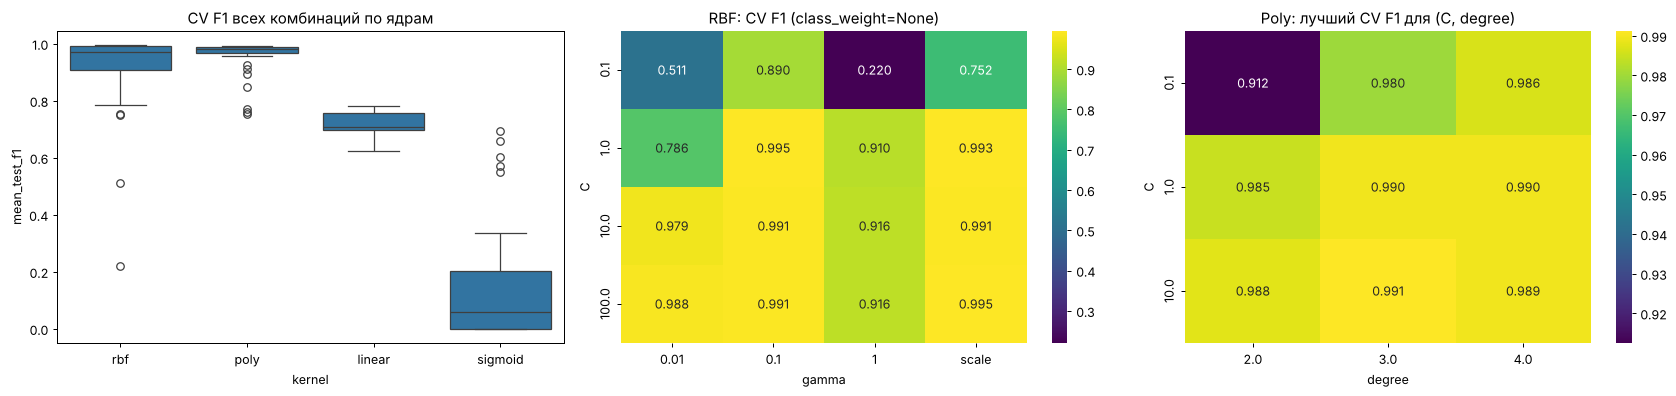

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(19, 4.5))

# 1) Разброс CV F1 по ядрам
order = best_per_kernel['kernel'].tolist()
sns.boxplot(data=svm_res, x='kernel', y='mean_test_f1', order=order, ax=axes[0])
axes[0].set_title('CV F1 всех комбинаций по ядрам')

# 2) RBF: тепловая карта C × gamma
best_cw = svm_gs.best_params_['svc__class_weight'] if svm_gs.best_params_['svc__kernel'] == 'rbf' else 'balanced'
r = svm_res[(svm_res.kernel == 'rbf') & (svm_res.class_weight == str(best_cw))]
sns.heatmap(r.pivot_table(index='C', columns=r['gamma'].astype(str), values='mean_test_f1'),
            annot=True, fmt='.3f', cmap='viridis', ax=axes[1])
axes[1].set_title(f'RBF: CV F1 (class_weight={best_cw})')

# 3) Poly: степень × C
r = svm_res[svm_res.kernel == 'poly']
sns.heatmap(r.pivot_table(index='C', columns='degree', values='mean_test_f1', aggfunc='max'),
            annot=True, fmt='.3f', cmap='viridis', ax=axes[2])
axes[2].set_title('Poly: лучший CV F1 для (C, degree)')
plt.tight_layout(); plt.show()

### A.3. Переобучение лучших моделей на всём train, метрики и число опорных векторов
Лучшую по CV модель каждого ядра переобучаем на всём обучающем множестве и для каждой считаем метрики на train и test, а также число опорных векторов (всего и по классам).

In [13]:
def params_from_row(row):
    p = {'svc__kernel': row['kernel'], 'svc__C': row['C'],
         'svc__class_weight': None if row['class_weight'] == 'None' else row['class_weight']}
    for k in ['gamma', 'degree', 'coef0']:
        if not pd.isna(row[k]):
            p['svc__' + k] = int(row[k]) if k == 'degree' else row[k]
    return p

svm_models, rows = {}, []
for _, row in best_per_kernel.iterrows():
    t0 = time.time()
    m = clone(svm_pipe).set_params(**params_from_row(row)).fit(X_train, y_train)
    svm_models[row['kernel']] = m
    svc = m.named_steps['svc']
    for part, Xp, yp in [('train', X_train, y_train), ('test', X_test, y_test)]:
        rows.append(dict(kernel=row['kernel'], sample=part, **metrics_row(yp, m.predict(Xp)),
                         n_SV=svc.n_support_.sum(), n_SV_class0=svc.n_support_[0], n_SV_class1=svc.n_support_[1],
                         SV_share=svc.n_support_.sum() / len(X_train), fit_s=time.time() - t0))
svm_summary = pd.DataFrame(rows).set_index(['kernel', 'sample']).round(4)
svm_summary

accuracy  precision  recall      f1  n_SV  n_SV_class0  n_SV_class1  SV_share   fit_s
kernel  sample                                                                                       
rbf     train     0.9989     0.9962  0.9924  0.9943   238          139           99    0.0289  0.1671
        test      1.0000     1.0000  1.0000  1.0000   238          139           99    0.0289  0.2008
poly    train     0.9998     0.9975  1.0000  0.9987    83           50           33    0.0101  0.0762
        test      0.9996     1.0000  0.9962  0.9981    83           50           33    0.0101  0.0860
linear  train     0.9646     0.8718  0.7396  0.8003   777          389          388    0.0943  1.3895
        test      0.9662     0.8977  0.7311  0.8058   777          389          388    0.0943  1.4321
sigmoid train     0.9535     0.9096  0.5727  0.7029  1311          657          654    0.1590  0.8783
        test      0.9516     0.9172  0.5455  0.6841  1311          657          654    0.1590  1.0007

ЛУЧШИЙ SVM: SVC(cache_size=1000, gamma=0.1)
Опорных векторов: 238 из 8244 (2.9%); класс 0: 139, класс 1: 99


accuracy  precision  recall      f1
model     sample                                     
SVM (rbf) train     0.9989     0.9962  0.9924  0.9943
          test      1.0000     1.0000  1.0000  1.0000

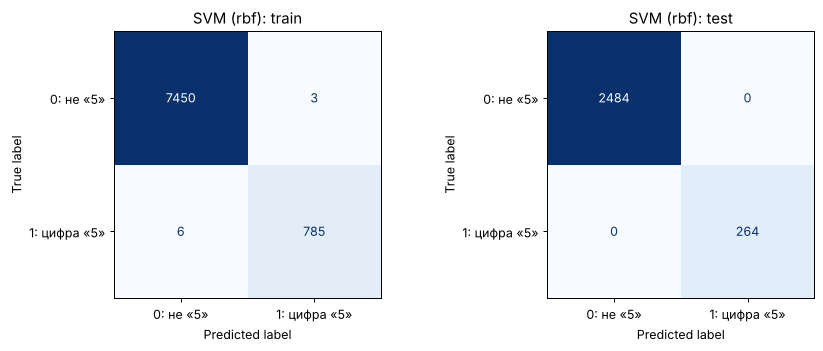

Classification report (SVM (rbf), test):
              precision    recall  f1-score   support

   0: не «5»     1.0000    1.0000    1.0000      2484
1: цифра «5»     1.0000    1.0000    1.0000       264

    accuracy                         1.0000      2748
   macro avg     1.0000    1.0000    1.0000      2748
weighted avg     1.0000    1.0000    1.0000      2748



In [14]:
best_kernel = svm_gs.best_params_['svc__kernel']
best_svm = svm_models[best_kernel]
best_svc = best_svm.named_steps['svc']
print('ЛУЧШИЙ SVM:', best_svc)
print(f'Опорных векторов: {best_svc.n_support_.sum()} из {len(X_train)} '
      f'({best_svc.n_support_.sum() / len(X_train):.1%}); класс 0: {best_svc.n_support_[0]}, класс 1: {best_svc.n_support_[1]}')
display(evaluate(best_svm, f'SVM ({best_kernel})'))
show_confusion(best_svm, f'SVM ({best_kernel})')

**Выводы по A.1–A.3** (в скобках — значения из контрольного прогона; при другой версии библиотек они могут немного отличаться):
* **RBF-ядро** — лучшее по CV (`C=1`, `gamma=0.1`, CV F1 ≈ 0.995). После переобучения на всём train модель на test не ошиблась ни разу (F1 = 1.0).
* **Полиномиальное ядро** (степень 3, `coef0=1`) почти не уступает RBF (F1 на test ≈ 0.998). При этом у него меньше всего опорных векторов (≈ 80, то есть около 1 % train).
* **Линейное ядро** заметно хуже (F1 ≈ 0.80, recall ≈ 0.73): цифру «5» нельзя хорошо отделить от остальных цифр гиперплоскостью в исходном 16-мерном пространстве.
* **Сигмоидное ядро** — самое слабое. С параметрами по умолчанию оно вообще не находит класс 1 (F1 = 0), после подбора параметров F1 ≈ 0.68. Это ядро не является положительно определённым (не удовлетворяет условию Мерсера) и плохо подходит для таких данных.
* **Число опорных векторов** показывает, насколько сложна граница для данного ядра. У RBF их около 240 (≈ 3 % train), у линейного ≈ 780 (≈ 9 %), у сигмоидного ≈ 1300 (≈ 16 %). Чем хуже ядро соответствует данным, тем больше точек попадает внутрь мягкого зазора. Тепловая карта показывает, что при малом `C` (широкий зазор) качество RBF падает.
* `class_weight='balanced'` на этих данных почти ничего не меняет: классы разделяются настолько хорошо, что перевзвешивание не требуется.
* Метрики на train и test почти совпадают — переобучения нет.

### A.4. Визуализация: t-SNE, UMAP, TriMap, PaCMAP

Набор точек для визуализации:
* **train**: все опорные векторы лучшего SVM (не более `MAX_SV_IN_VIZ`) и случайные train-объекты, всего `VIZ_TRAIN_SIZE`;
* **test**: стратифицированная подвыборка из `VIZ_TEST_SIZE` объектов.

Вложения строятся по стандартизованным признакам **один раз** и используются повторно в частях B и C. Поэтому рисунки трёх классификаторов можно сравнивать напрямую.

На рисунках: синие кружки — класс 0, оранжевые треугольники — класс 1. Опорные векторы класса 0 обведены тёмно-синими квадратами, класса 1 — тёмно-красными ромбами. Чёрный крестик — ошибка классификатора.

In [15]:
rng = np.random.RandomState(RANDOM_STATE)
sv_idx = best_svc.support_                       # индексы опорных векторов в X_train
if len(sv_idx) > MAX_SV_IN_VIZ:
    sv_idx = rng.choice(sv_idx, MAX_SV_IN_VIZ, replace=False)
rest = np.setdiff1d(np.arange(len(X_train)), sv_idx)
n_rest = max(VIZ_TRAIN_SIZE - len(sv_idx), 0)
viz_train_idx = np.concatenate([sv_idx, rng.choice(rest, min(n_rest, len(rest)), replace=False)])
_, viz_test_idx = train_test_split(np.arange(len(X_test)), test_size=min(VIZ_TEST_SIZE, len(X_test) - 2),
                                   stratify=y_test, random_state=RANDOM_STATE)

X_viz = np.vstack([X_train[viz_train_idx], X_test[viz_test_idx]])
y_viz = np.concatenate([y_train[viz_train_idx], y_test[viz_test_idx]])
is_test_viz = np.r_[np.zeros(len(viz_train_idx), bool), np.ones(len(viz_test_idx), bool)]
sv_mask_viz = np.r_[np.isin(viz_train_idx, best_svc.support_), np.zeros(len(viz_test_idx), bool)]
print(f'Точек: {len(X_viz)} (train {(~is_test_viz).sum()}, test {is_test_viz.sum()}), '
      f'опорных векторов на рисунках: {sv_mask_viz.sum()}')

X_viz_scaled = StandardScaler().fit(X_train).transform(X_viz)
t0 = time.time()
EMBS = compute_embeddings(X_viz_scaled)
print(f'Всего на вложения: {time.time() - t0:.1f} c')

Точек: 2500 (train 1500, test 1000), опорных векторов на рисунках: 238


t-SNE   [perplexity=10]: 6.1 c


t-SNE   [perplexity=30]: 6.5 c


t-SNE   [perplexity=50]: 8.1 c


UMAP    [n_neighbors=5, min_dist=0.05]: 15.6 c


...

TriMap  [n_inliers=12, n_outliers=4, n_random=3]: 1.4 c


TriMap  [n_inliers=25, n_outliers=8, n_random=5]: 4.5 c


PaCMAP  [n_neighbors=5, MN_ratio=0.5, FP_ratio=2.0]: 0.4 c


PaCMAP  [n_neighbors=10, MN_ratio=0.5, FP_ratio=2.0]: 0.6 c


PaCMAP  [n_neighbors=30, MN_ratio=1.0, FP_ratio=4.0]: 2.7 c
Всего на вложения: 73.6 c


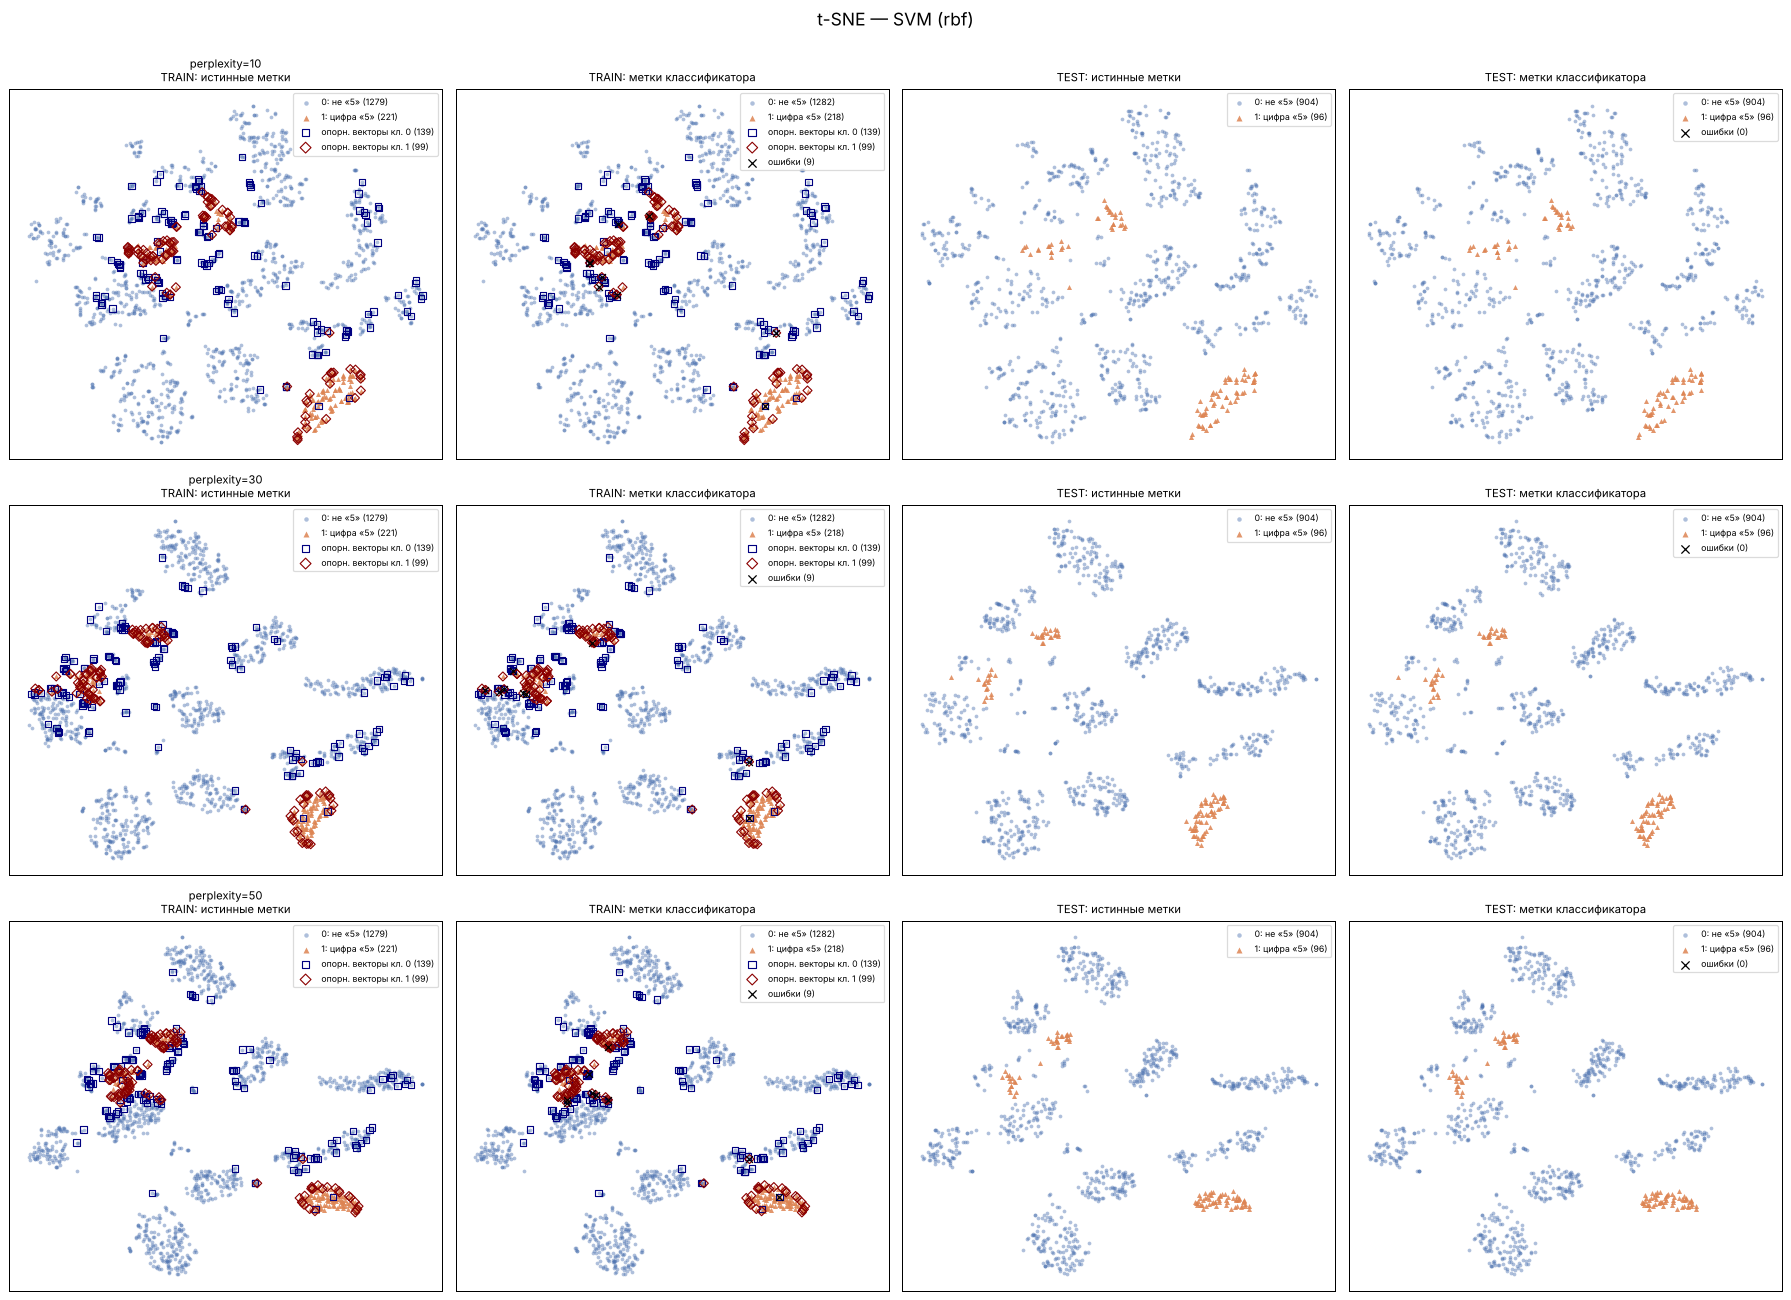

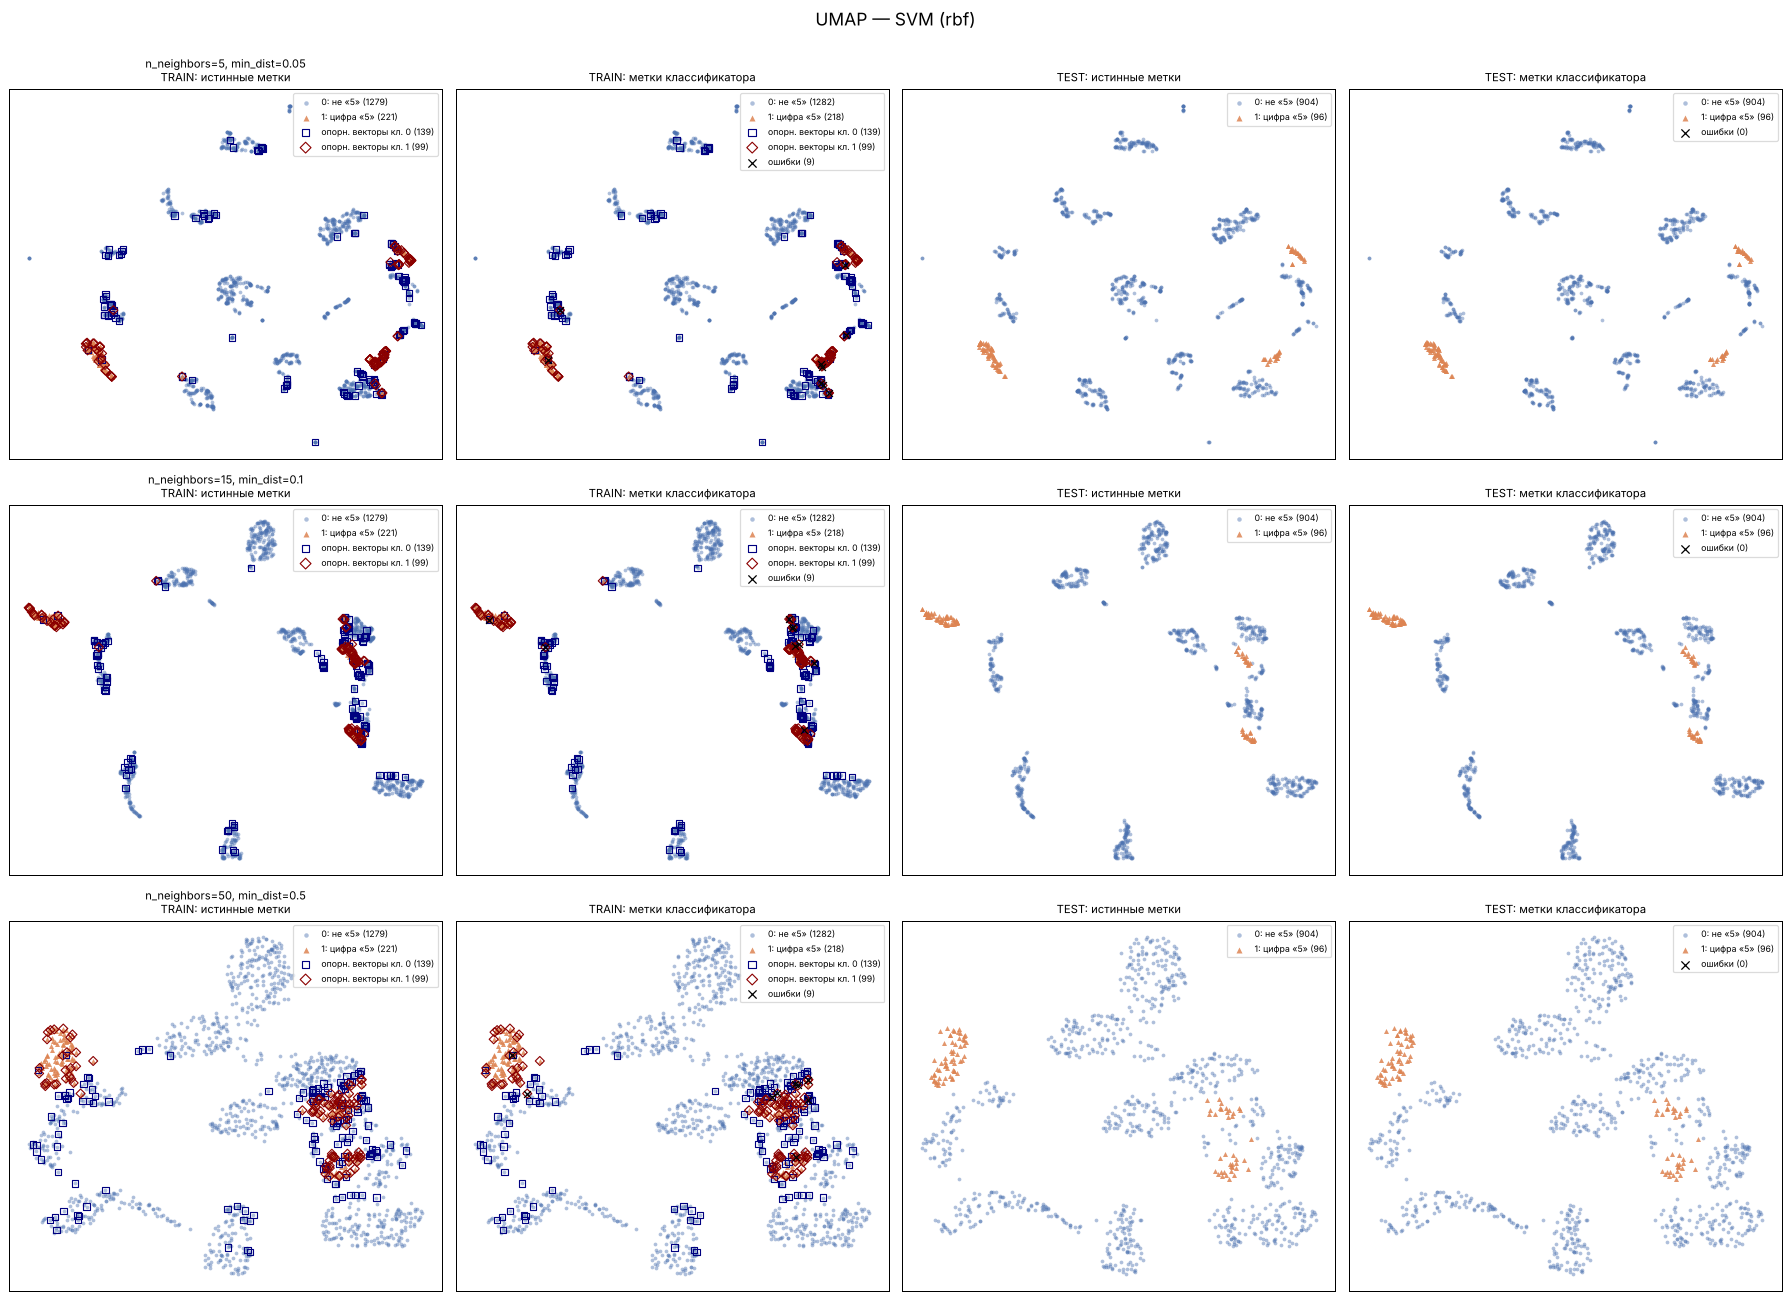

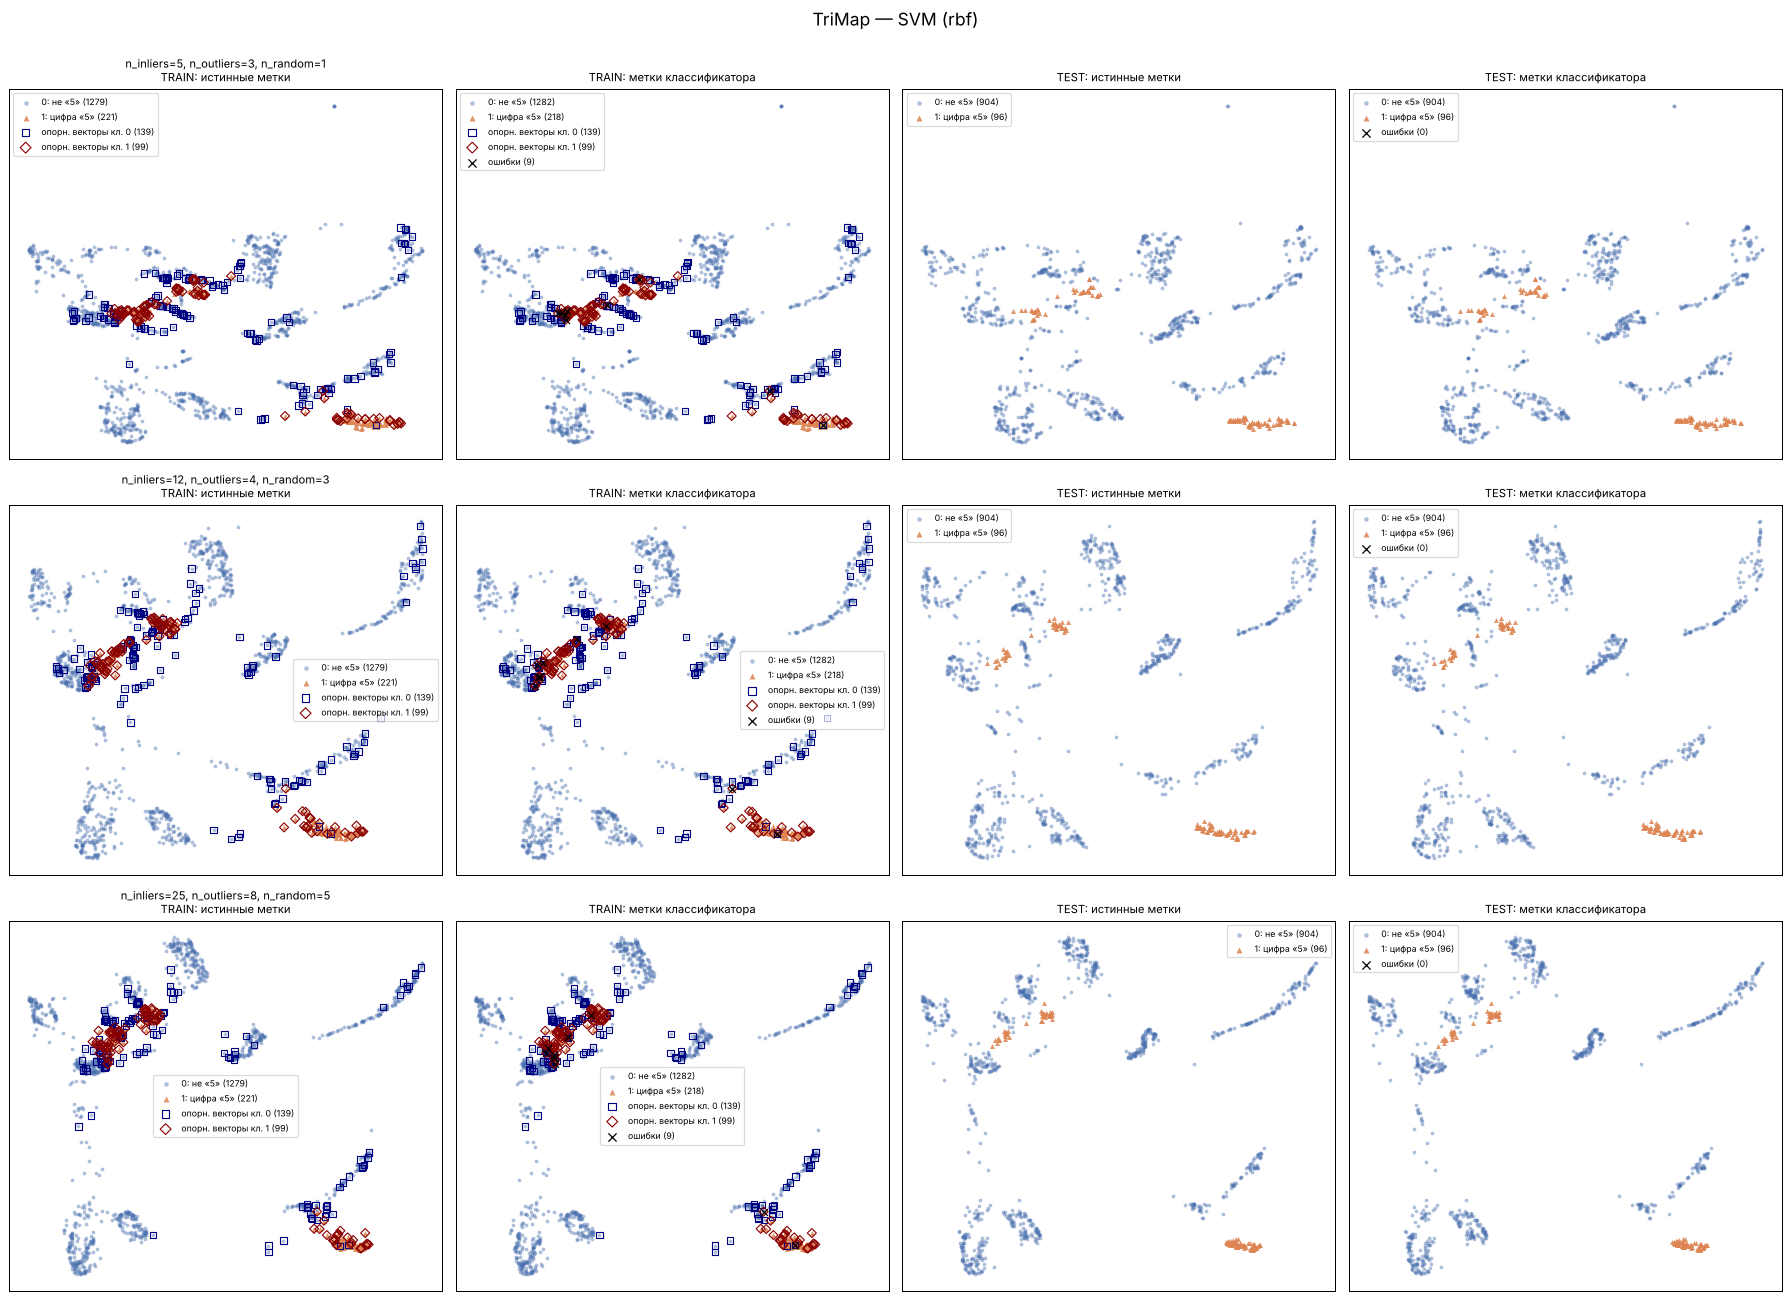

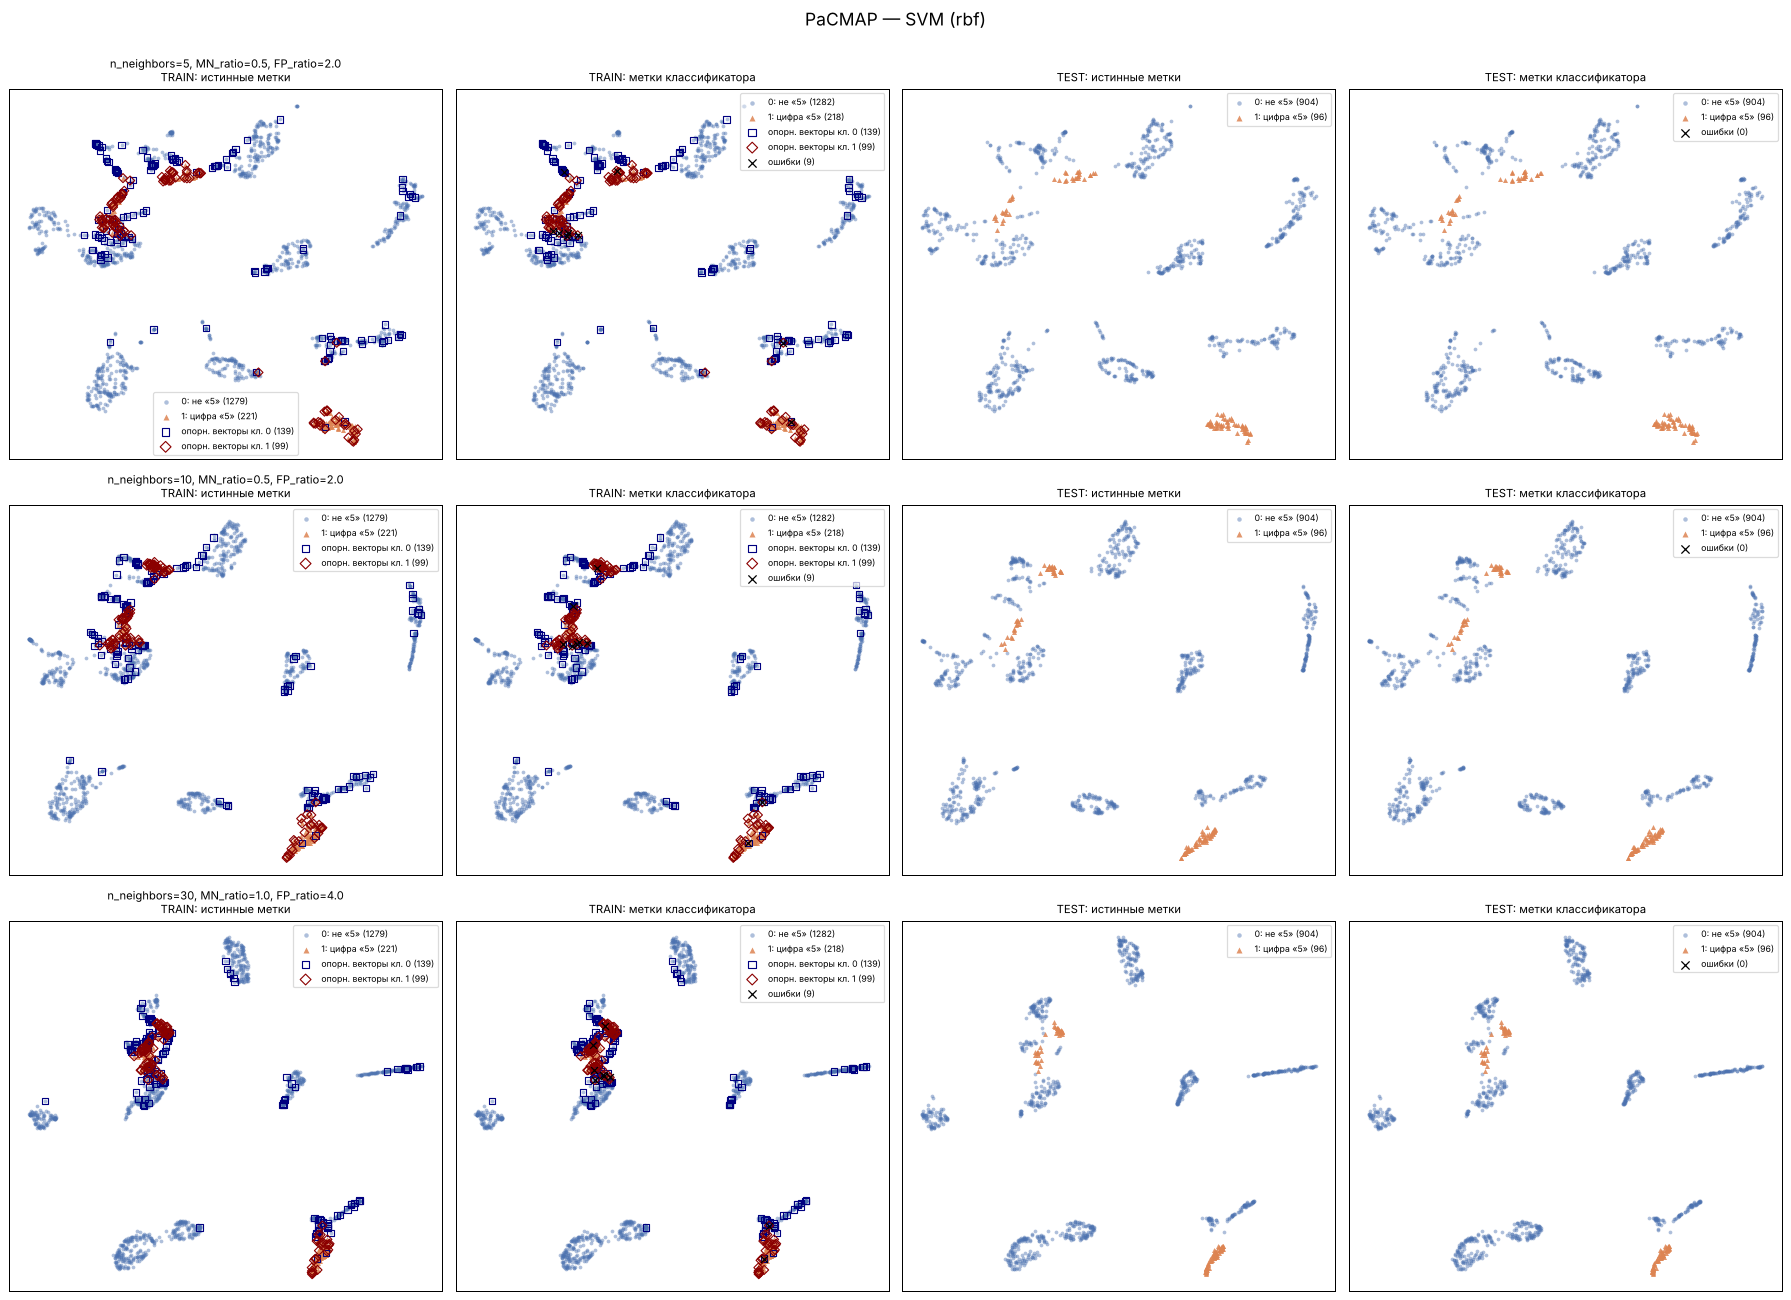

In [16]:
y_pred_viz_svm = best_svm.predict(X_viz)
plot_embeddings(EMBS, y_pred_viz_svm, f'SVM ({best_kernel})', sv_mask=sv_mask_viz)

**Что видно на рисунках:**
* Все четыре метода показывают класс «5» как **2–3 отдельных компактных кластера**. Они соответствуют разным манерам написания цифры, например «5» в один штрих и с отдельной верхней перекладиной (см. примеры траекторий выше).
* Опорные векторы класса 1 лежат **на краях кластеров «5»**. Опорные векторы класса 0 — это объекты других цифр, оказавшиеся рядом с «5», а также граничные точки других кластеров. Внутри однородных областей опорных векторов почти нет — так и должно быть, решение SVM определяется только граничными точками.
* Рисунки с истинными и с предсказанными метками практически совпадают. На train немногочисленные ошибки (крестики) находятся в зонах контакта кластеров, на test ошибок нет.
* Влияние параметров методов:
  * **t-SNE**: малая `perplexity` дробит данные на много мелких кластеров, большая лучше передаёт глобальную структуру;
  * **UMAP**: малые `n_neighbors` и `min_dist` дают плотные, хорошо разделённые сгустки, большие — более «размазанную» картину с сохранением глобальной формы;
  * **TriMap**: при большем числе триплетов (`n_inliers`, `n_outliers`) глобальное расположение кластеров устойчивее;
  * **PaCMAP**: при большем `n_neighbors`, `MN_ratio` и `FP_ratio` кластеры сильнее раздвигаются.

---
# Часть B. kNN-классификатор

kNN основан на расстояниях, поэтому признаки обязательно масштабируются (`StandardScaler` в `Pipeline`).

Сетка:
* **число соседей** `n_neighbors`: 1, 3, 5, 7, 9, 11, 15, 21, 31;
* **метрика расстояния**: евклидова (L2), манхэттенская (L1), Чебышёва (L∞), Минковского с p = 3, косинусная;
* **правило голосования** `weights`: `uniform` — простое большинство среди k соседей; `distance` — голос соседа взвешивается величиной 1/расстояние.

Объектов немного (~8 тыс.), признаков 16, поэтому сетка перебирается на **всём train** с 5-кратной CV.

In [17]:
knn_pipe = Pipeline([('scaler', StandardScaler()), ('knn', KNeighborsClassifier())])
K_LIST = [1, 3, 5, 7, 9, 11, 15, 21, 31]
knn_grid = [
    {'knn__n_neighbors': K_LIST, 'knn__weights': ['uniform', 'distance'],
     'knn__metric': ['euclidean', 'manhattan', 'chebyshev', 'cosine']},
    {'knn__n_neighbors': K_LIST, 'knn__weights': ['uniform', 'distance'],
     'knn__metric': ['minkowski'], 'knn__p': [3]},
]
n_comb = sum(np.prod([len(v) for v in g.values()]) for g in knn_grid)
print(f'Комбинаций: {n_comb}, обучений: {n_comb * CV_FOLDS}')

# return_train_score=False: на train у kNN при k=1 / weights='distance' метрики всегда = 1,
# а предсказание всех обучающих фолдов в несколько раз замедлило бы перебор
knn_gs = GridSearchCV(knn_pipe, knn_grid, scoring=SCORING, refit='f1', cv=cv, n_jobs=N_JOBS)
t0 = time.time(); knn_gs.fit(X_train, y_train)
print(f'Grid search kNN: {time.time() - t0:.1f} c')
print('Лучшие параметры:', knn_gs.best_params_)
print('Лучший CV F1   : %.4f' % knn_gs.best_score_)
KNN_PARAMS = ['knn__n_neighbors', 'knn__metric', 'knn__p', 'knn__weights']
cv_table(knn_gs, KNN_PARAMS, top=15)

Комбинаций: 90, обучений: 450


Grid search kNN: 145.9 c
Лучшие параметры: {'knn__metric': 'cosine', 'knn__n_neighbors': 1, 'knn__weights': 'uniform'}
Лучший CV F1   : 0.9937


,n_neighbors,metric,p,weights,mean_test_accuracy,mean_test_precision,mean_test_recall,mean_test_f1,mean_fit_time
54,1,cosine,NaN,uniform,0.9988,0.9937,0.9937,0.9937,0.0045
55,1,cosine,NaN,distance,0.9988,0.9937,0.9937,0.9937,0.0042
18,1,manhattan,NaN,uniform,0.9987,0.9924,0.9937,0.9930,0.0043
19,1,manhattan,NaN,distance,0.9987,0.9924,0.9937,0.9930,0.0040
21,3,manhattan,NaN,distance,0.9987,0.9949,0.9912,0.9930,0.0044
61,7,cosine,NaN,distance,0.9985,0.9925,0.9924,0.9924,0.0049
63,9,cosine,NaN,distance,0.9985,0.9925,0.9924,0.9924,0.0041
65,11,cosine,NaN,distance,0.9985,0.9925,0.9924,0.9924,0.0042
20,3,manhattan,NaN,uniform,0.9985,0.9937,0.9912,0.9924,0.0043
57,3,cosine,NaN,distance,0.9985,0.9937,0.9911,0.9924,0.0041


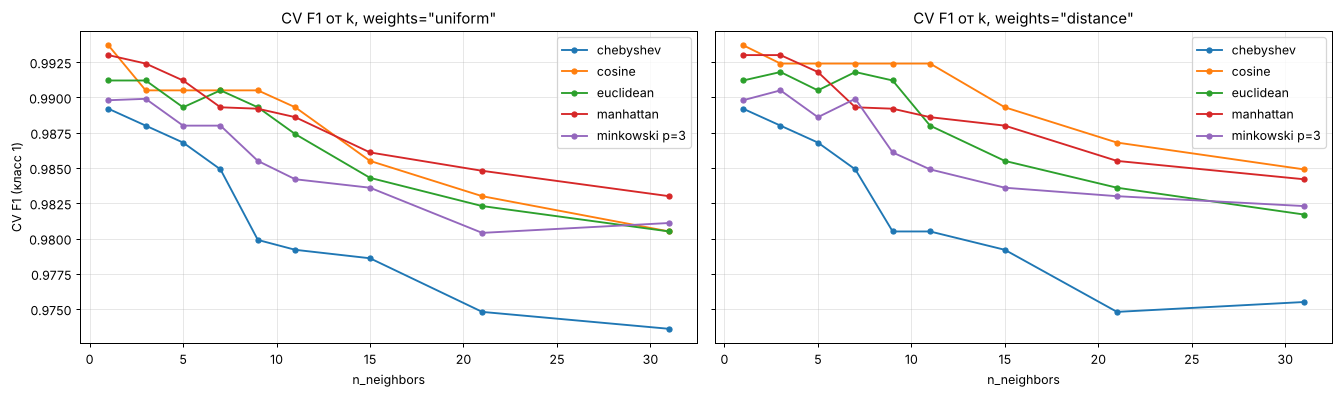

Лучший CV F1 для каждой пары (метрика, голосование):


weights,distance,uniform
metric_name,,
chebyshev,0.9892,0.9892
cosine,0.9937,0.9937
euclidean,0.9918,0.9912
manhattan,0.9930,0.9930
minkowski p=3,0.9905,0.9899


In [18]:
knn_res = cv_table(knn_gs, KNN_PARAMS)
knn_res['metric_name'] = np.where(knn_res['metric'] == 'minkowski', 'minkowski p=3', knn_res['metric'])
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), sharey=True)
for ax, w in zip(axes, ['uniform', 'distance']):
    for mname, g in knn_res[knn_res.weights == w].groupby('metric_name'):
        g = g.sort_values('n_neighbors')
        ax.plot(g['n_neighbors'], g['mean_test_f1'], '-o', ms=4, label=mname)
    ax.set_title(f'CV F1 от k, weights="{w}"'); ax.set_xlabel('n_neighbors'); ax.grid(alpha=.3); ax.legend()
axes[0].set_ylabel('CV F1 (класс 1)')
plt.tight_layout(); plt.show()

print('Лучший CV F1 для каждой пары (метрика, голосование):')
knn_res.pivot_table(index='metric_name', columns='weights', values='mean_test_f1', aggfunc='max').round(4)

ЛУЧШИЙ kNN: KNeighborsClassifier(metric='cosine', n_neighbors=1)


accuracy  precision  recall   f1
model sample                                  
kNN   train        1.0        1.0     1.0  1.0
      test         1.0        1.0     1.0  1.0

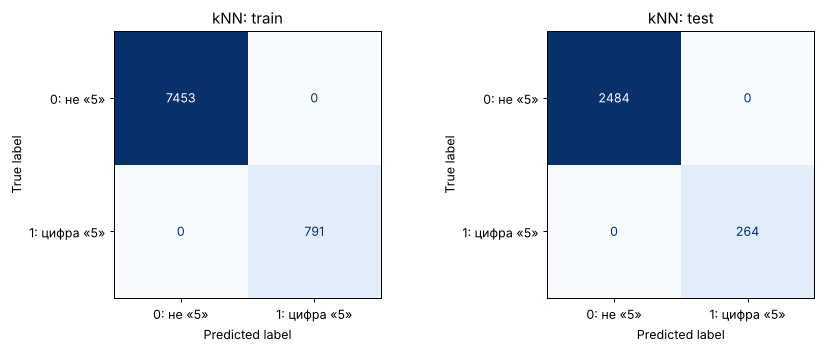

Classification report (kNN, test):


              precision    recall  f1-score   support

   0: не «5»     1.0000    1.0000    1.0000      2484
1: цифра «5»     1.0000    1.0000    1.0000       264

    accuracy                         1.0000      2748
   macro avg     1.0000    1.0000    1.0000      2748
weighted avg     1.0000    1.0000    1.0000      2748



In [19]:
best_knn = knn_gs.best_estimator_      # refit=True: уже переобучен на всём train
print('ЛУЧШИЙ kNN:', best_knn.named_steps['knn'])
display(evaluate(best_knn, 'kNN'))
show_confusion(best_knn, 'kNN')

**Выводы по kNN:**
* Точнее всего работают **малые k** (1–3). С ростом k F1 монотонно падает: классы хорошо разделены локально, а при большом k голоса многочисленного класса 0 «перекрикивают» соседей-«пятёрок», и recall снижается.
* Лучшей оказалась **косинусная** метрика (k=1, CV F1 ≈ 0.994), чуть хуже манхэттенская (≈ 0.993). Евклидова и Минковского с p=3 немного уступают, а метрика Чебышёва — худшая (≈ 0.989): она учитывает только одну наибольшую разность координат.
* При k=1 правило голосования роли не играет (сосед один). При k ≥ 5 голосование `distance` стабильно не хуже `uniform`: дальние соседи слабо влияют на ответ, поэтому F1 падает медленнее.
* На test лучшая модель kNN не ошиблась ни разу (F1 = 1.0).
* При `weights='distance'` или `k=1` метрики **на train равны 1.0**: каждый обучающий объект является своим ближайшим соседем с нулевым расстоянием. Это свойство метода, о качестве модели говорят только метрики на test и CV.

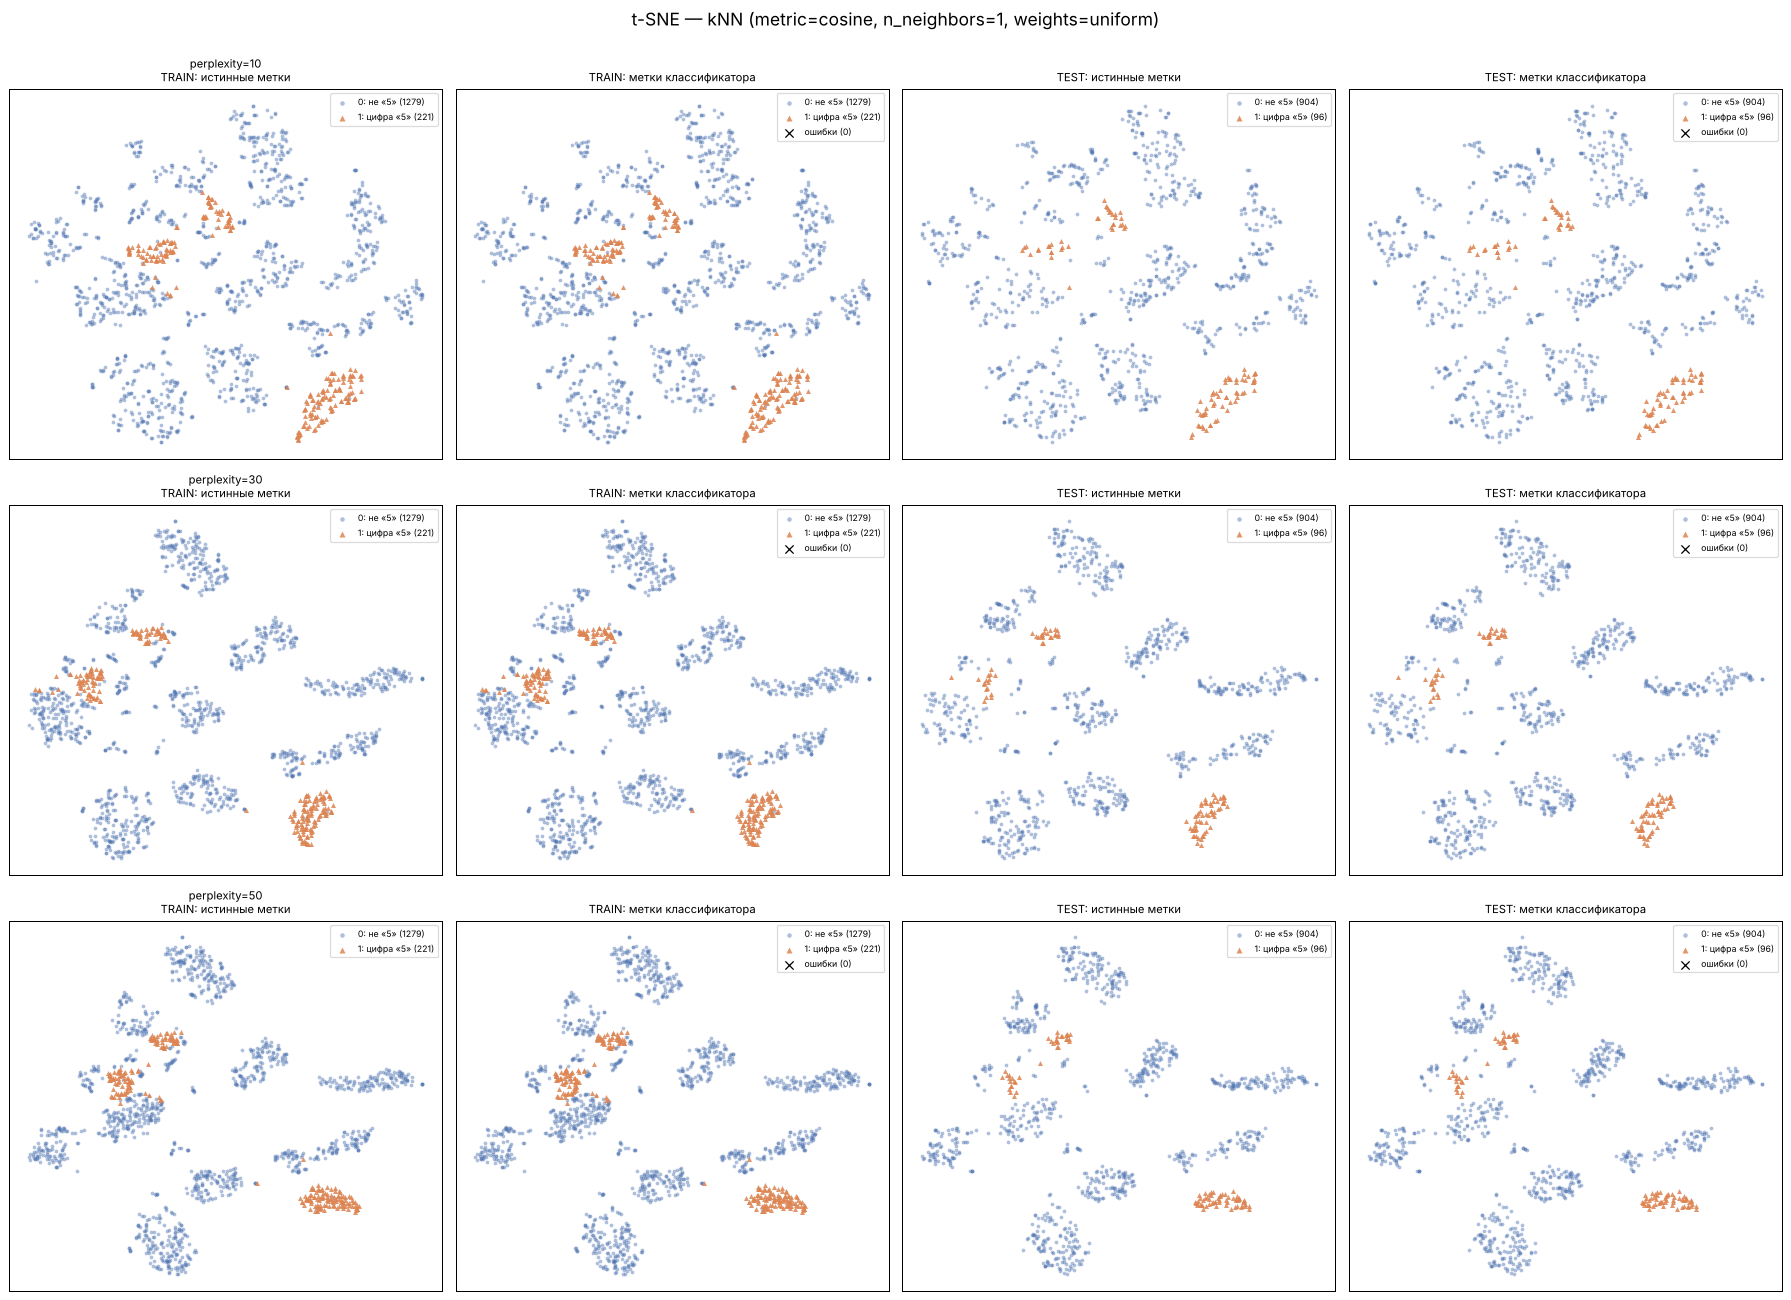

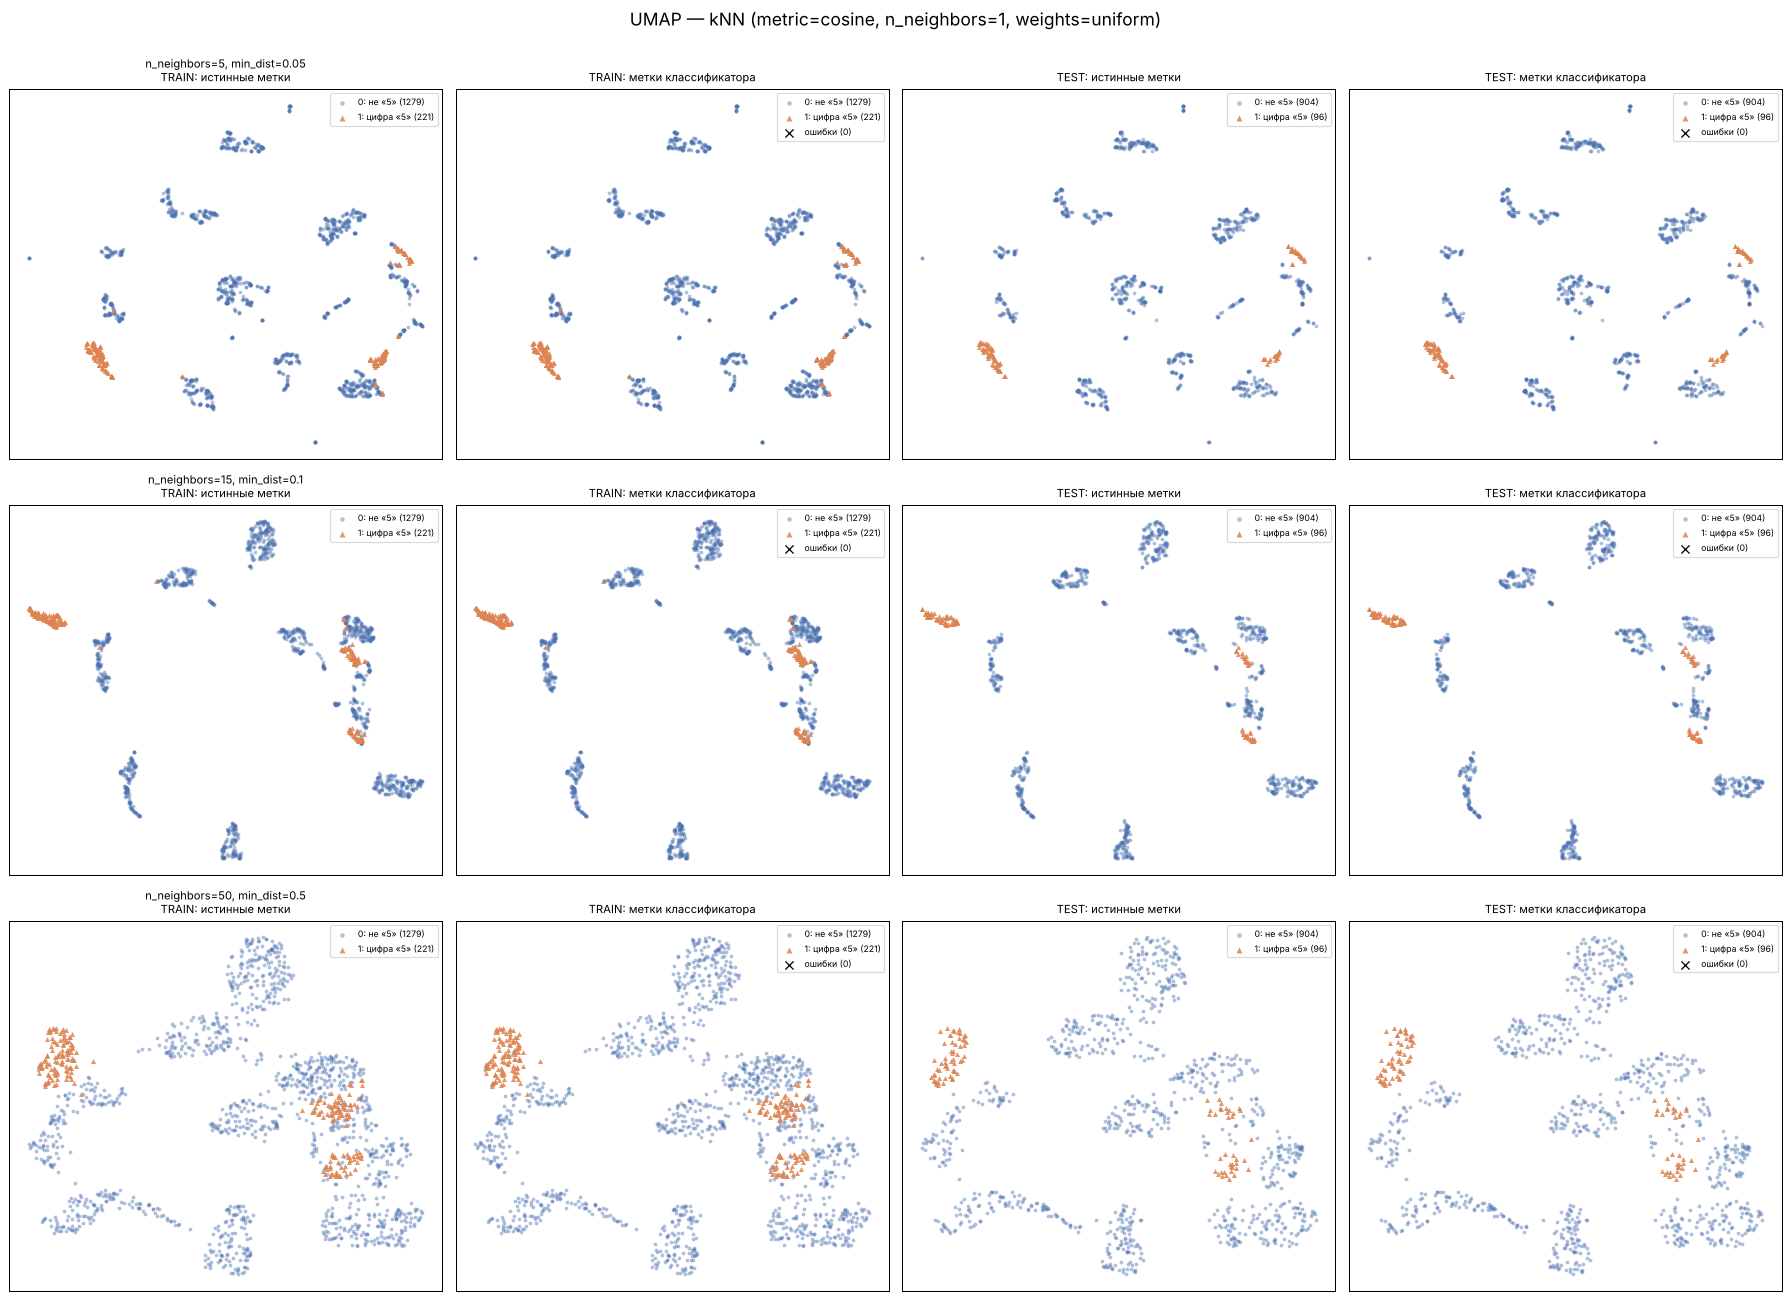

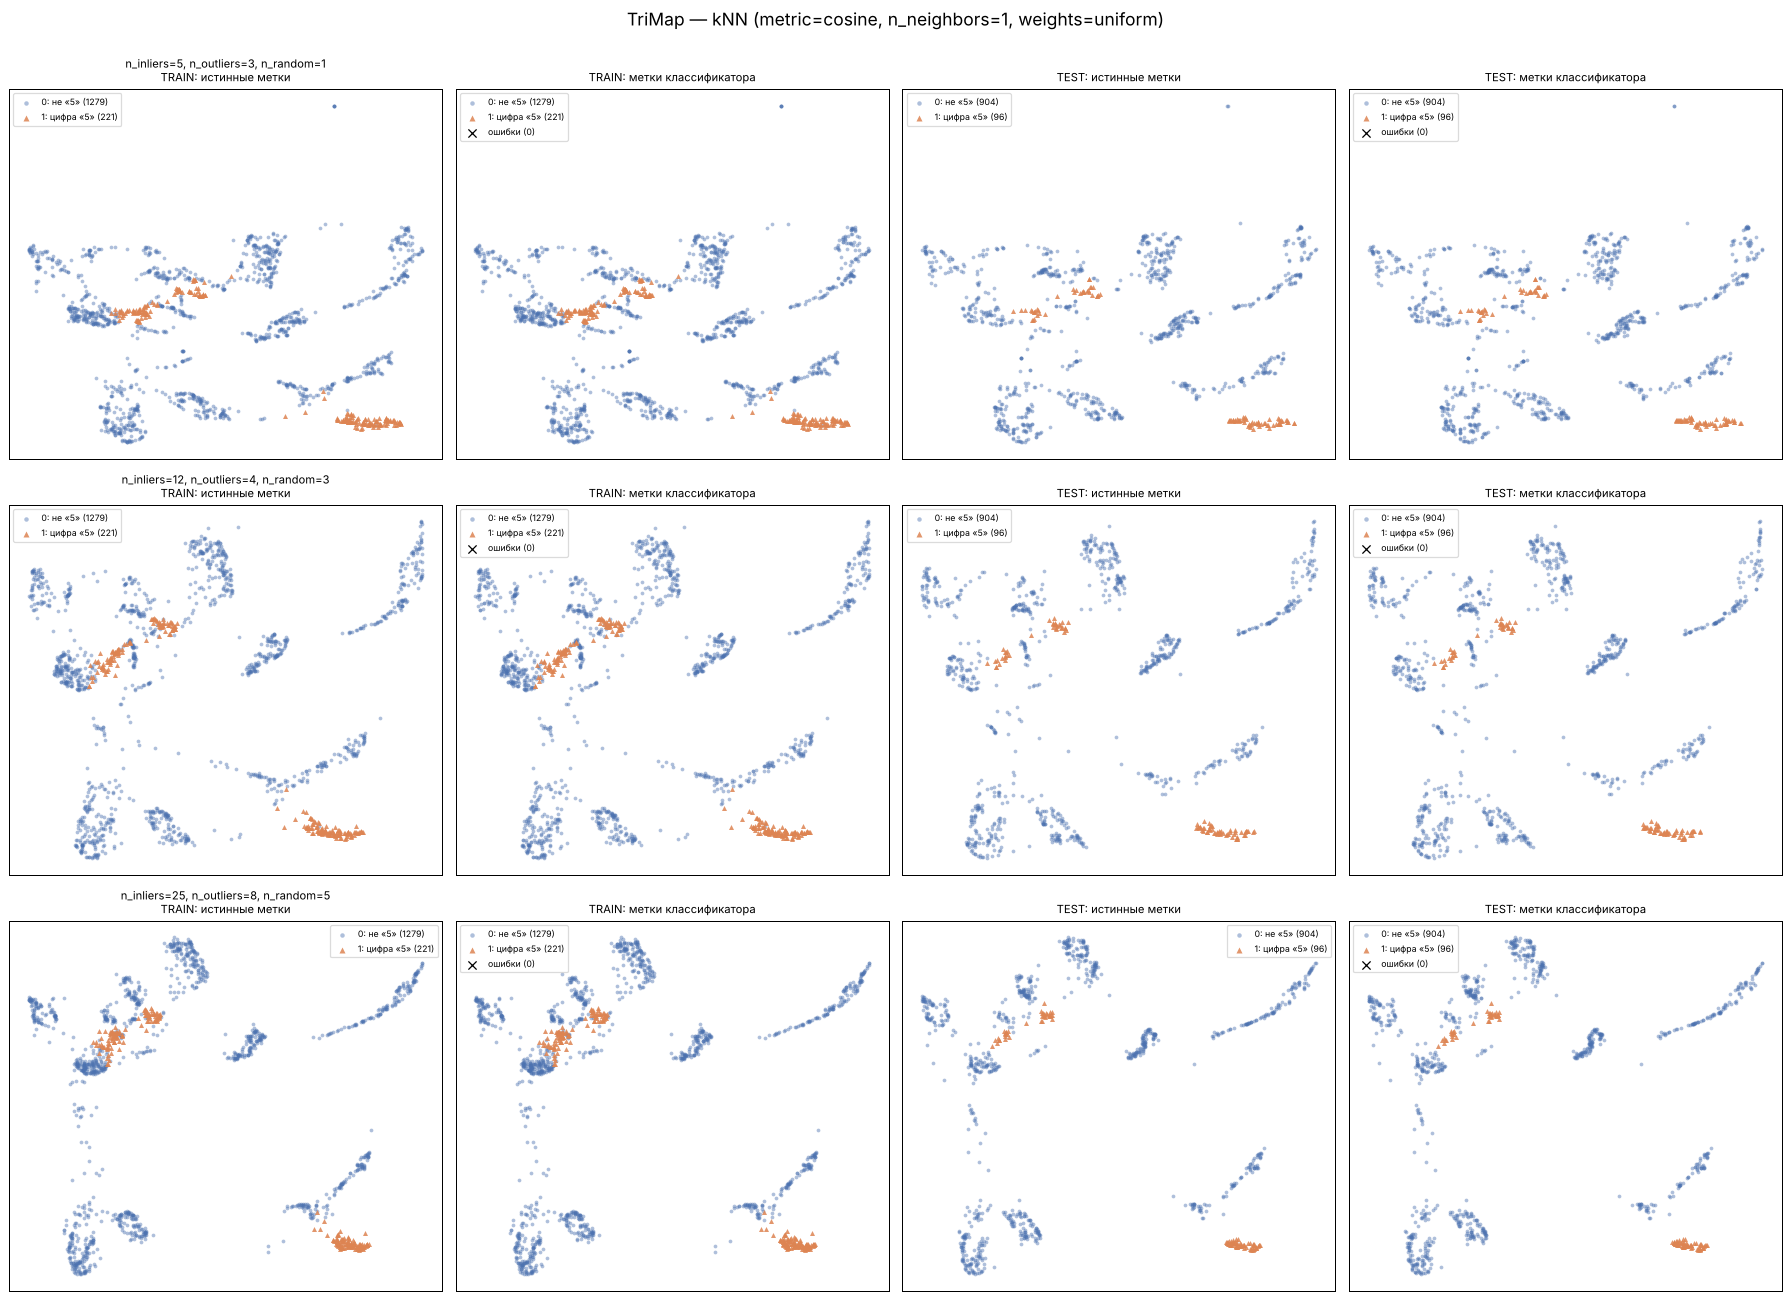

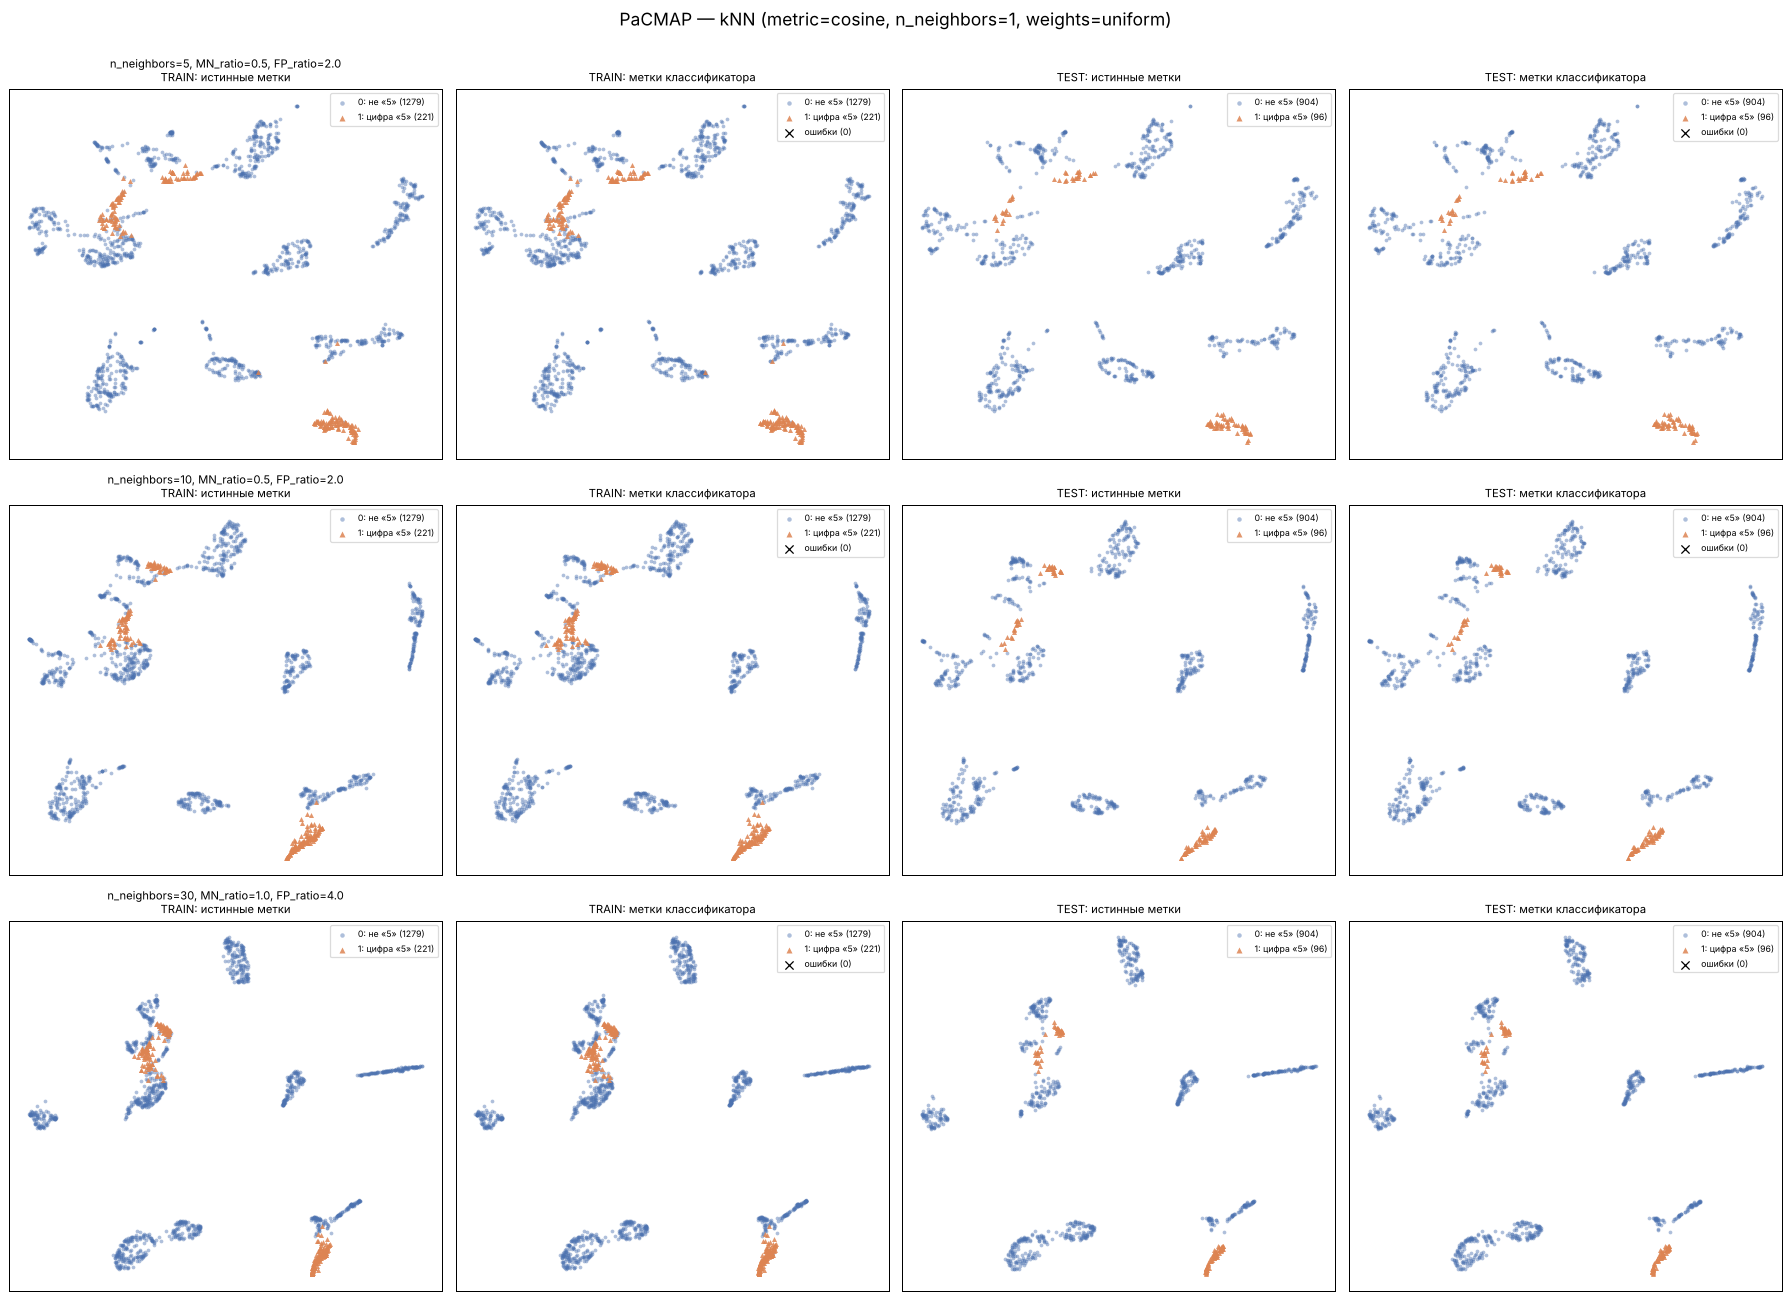

In [20]:
y_pred_viz_knn = best_knn.predict(X_viz)
plot_embeddings(EMBS, y_pred_viz_knn, 'kNN (' + ', '.join(f'{k.split("__")[1]}={v}' for k, v in knn_gs.best_params_.items()) + ')')

Вложения те же, что в части A, поэтому рисунки можно сравнивать с SVM напрямую. При k=1 на train ошибок нет по построению: ближайший сосед объекта — он сам. На test лучший kNN тоже не ошибся. Если бы ошибки были, они пришлись бы на одиночные объекты внутри «чужого» кластера: у такого объекта ближайшие соседи принадлежат другому классу.

---
# Часть C. Random Forest

Деревья решений не зависят от масштаба признаков, поэтому стандартизация не нужна.

Перебираемые параметры (аналоги «соседей и метрик» из текста задания, см. примечание в начале):
* `n_estimators` — число деревьев в лесу;
* `max_depth` — максимальная глубина дерева;
* `criterion` — критерий качества разбиения: `gini` или `entropy`;
* `max_features` — сколько признаков рассматривается при каждом разбиении: `sqrt` (4 из 16) или 0.5 (8 из 16);
* `min_samples_leaf` — минимальное число объектов в листе;
* `class_weight` — `None` или `balanced_subsample` (веса классов пересчитываются по каждой бутстрэп-выборке).

**Правило голосования.** `RandomForestClassifier` в sklearn использует *мягкое* голосование: вероятности классов усредняются по деревьям. После grid search оно сравнивается с *жёстким* голосованием (простое большинство голосов деревьев).

In [21]:
rf_grid = {
    'n_estimators': [50, 150],
    'max_depth': [None, 12],
    'criterion': ['gini', 'entropy'],
    'max_features': ['sqrt', 0.5],
    'min_samples_leaf': [1, 4],
    'class_weight': [None, 'balanced_subsample'],
}
n_comb = np.prod([len(v) for v in rf_grid.values()])
print(f'Комбинаций: {n_comb}, обучений: {n_comb * RF_CV_FOLDS}')

rf_cv = StratifiedKFold(RF_CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
rf_gs = GridSearchCV(RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1), rf_grid,
                     scoring=SCORING, refit='f1', cv=rf_cv, n_jobs=N_JOBS, return_train_score=True)
t0 = time.time(); rf_gs.fit(X_train, y_train)
print(f'Grid search RF: {time.time() - t0:.1f} c')
print('Лучшие параметры:', rf_gs.best_params_)
print('Лучший CV F1   : %.4f' % rf_gs.best_score_)
RF_PARAMS = list(rf_grid)
cv_table(rf_gs, RF_PARAMS, top=15)

Комбинаций: 64, обучений: 192


Grid search RF: 77.4 c
Лучшие параметры: {'class_weight': 'balanced_subsample', 'criterion': 'entropy', 'max_depth': 12, 'max_features': 0.5, 'min_samples_leaf': 4, 'n_estimators': 150}
Лучший CV F1   : 0.9795


,n_estimators,max_depth,criterion,max_features,min_samples_leaf,class_weight,mean_test_accuracy,mean_test_precision,mean_test_recall,mean_test_f1,mean_train_f1,mean_fit_time
63,150,12,entropy,0.5,4,balanced_subsample,0.9961,0.9948,0.9646,0.9795,0.9984,1.2857
38,50,None,gini,0.5,4,balanced_subsample,0.9958,0.9935,0.9621,0.9775,0.9978,0.4490
62,50,12,entropy,0.5,4,balanced_subsample,0.9958,0.9935,0.9621,0.9775,0.9984,0.4274
51,150,None,entropy,sqrt,4,balanced_subsample,0.9958,0.9948,0.9608,0.9775,0.9984,0.8696
55,150,None,entropy,0.5,4,balanced_subsample,0.9958,0.9948,0.9608,0.9775,0.9984,1.2494
52,50,None,entropy,0.5,1,balanced_subsample,0.9958,0.9961,0.9596,0.9775,1.0000,0.4243
53,150,None,entropy,0.5,1,balanced_subsample,0.9958,0.9961,0.9596,0.9775,1.0000,1.2109
20,50,None,entropy,0.5,1,None,0.9958,0.9987,0.9570,0.9774,1.0000,0.4154
50,50,None,entropy,sqrt,4,balanced_subsample,0.9956,0.9948,0.9596,0.9768,0.9984,0.2856
58,50,12,entropy,sqrt,4,balanced_subsample,0.9956,0.9948,0.9596,0.9768,0.9978,0.3343


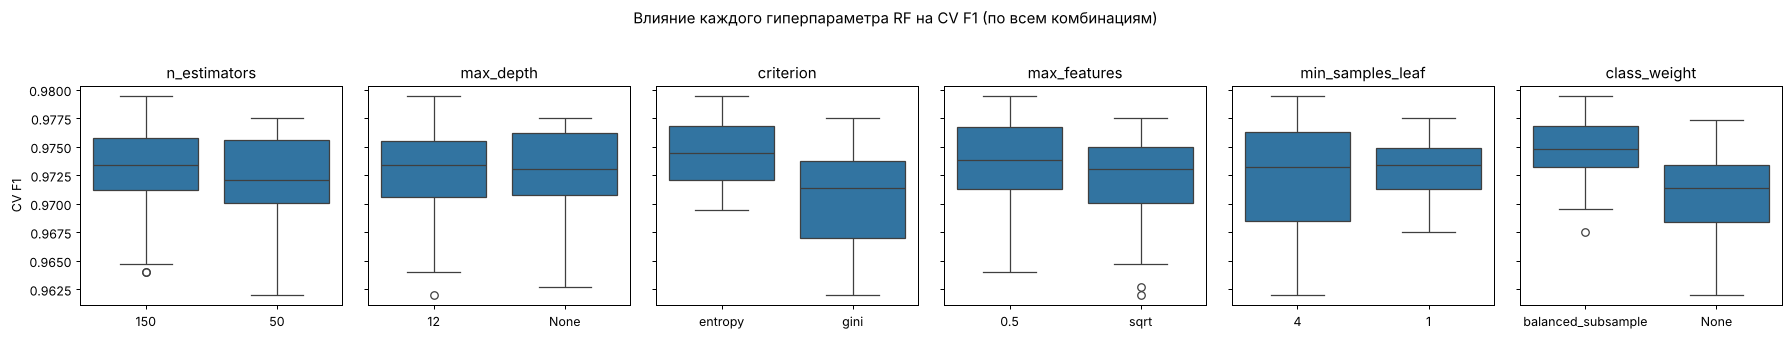

In [22]:
rf_res = cv_table(rf_gs, RF_PARAMS)
fig, axes = plt.subplots(1, len(RF_PARAMS), figsize=(20, 3.6), sharey=True)
for ax, p in zip(axes, RF_PARAMS):
    sns.boxplot(x=rf_res[p].astype(str), y=rf_res['mean_test_f1'], ax=ax)
    ax.set_title(p); ax.set_xlabel('')
axes[0].set_ylabel('CV F1')
plt.suptitle('Влияние каждого гиперпараметра RF на CV F1 (по всем комбинациям)', y=1.03)
plt.tight_layout(); plt.show()

ЛУЧШИЙ RF: RandomForestClassifier(class_weight='balanced_subsample', criterion='entropy',
                       max_depth=12, max_features=0.5, min_samples_leaf=4,
                       n_estimators=150, n_jobs=-1, oob_score=True,
                       random_state=42)
OOB accuracy: 0.9964


accuracy  precision  recall      f1
model         sample                                     
Random Forest train     0.9995      0.995  1.0000  0.9975
              test      0.9982      1.000  0.9811  0.9904

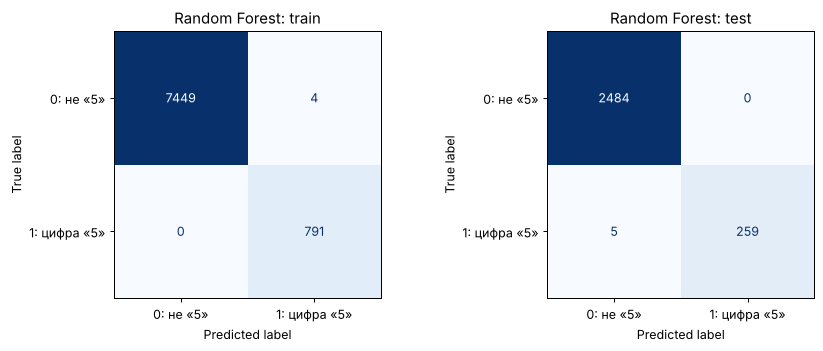

Classification report (Random Forest, test):
              precision    recall  f1-score   support

   0: не «5»     0.9980    1.0000    0.9990      2484
1: цифра «5»     1.0000    0.9811    0.9904       264

    accuracy                         0.9982      2748
   macro avg     0.9990    0.9905    0.9947      2748
weighted avg     0.9982    0.9982    0.9982      2748



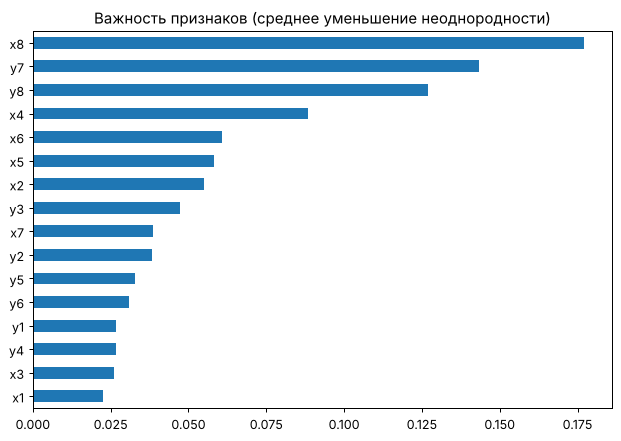

In [23]:
best_rf = clone(rf_gs.best_estimator_).set_params(oob_score=True, n_jobs=N_JOBS).fit(X_train, y_train)
print('ЛУЧШИЙ RF:', best_rf)
print('OOB accuracy: %.4f' % best_rf.oob_score_)
display(evaluate(best_rf, 'Random Forest'))
show_confusion(best_rf, 'Random Forest')

imp = pd.Series(best_rf.feature_importances_, index=FEATURE_NAMES).sort_values()
imp.plot.barh(figsize=(7, 5), title='Важность признаков (среднее уменьшение неоднородности)')
plt.tight_layout(); plt.show()

### C.1. Правила голосования: мягкое и жёсткое
* **soft** (по умолчанию в sklearn): $P(c\mid x)=\frac1T\sum_t p_t(c\mid x)$, ответ — $\arg\max_c$;
* **hard**: каждое дерево голосует за один класс, ответ — класс, набравший большинство голосов;
* дополнительно: мягкое голосование с порогом 0.3 вместо 0.5. Для несбалансированных данных снижение порога повышает recall редкого класса.

In [24]:
def rf_vote(model, Xp, rule):
    if rule == 'soft (0.5)':
        return model.predict(Xp)
    if rule == 'soft (0.3)':
        return (model.predict_proba(Xp)[:, 1] >= 0.3).astype(int)
    votes = np.stack([t.predict(Xp) for t in model.estimators_])   # (n_trees, n_samples), метки 0/1
    return (votes.mean(axis=0) > 0.5).astype(int)

rows = []
for rule in ['soft (0.5)', 'hard', 'soft (0.3)']:
    for part, Xp, yp in [('train', X_train, y_train), ('test', X_test, y_test)]:
        rows.append(dict(voting=rule, sample=part, **metrics_row(yp, rf_vote(best_rf, Xp, rule))))
pd.DataFrame(rows).set_index(['voting', 'sample']).round(4)

accuracy  precision  recall      f1
voting     sample                                     
soft (0.5) train     0.9995     0.9950  1.0000  0.9975
           test      0.9982     1.0000  0.9811  0.9904
hard       train     0.9995     0.9950  1.0000  0.9975
           test      0.9989     1.0000  0.9886  0.9943
soft (0.3) train     0.9992     0.9912  1.0000  0.9956
           test      0.9978     0.9850  0.9924  0.9887

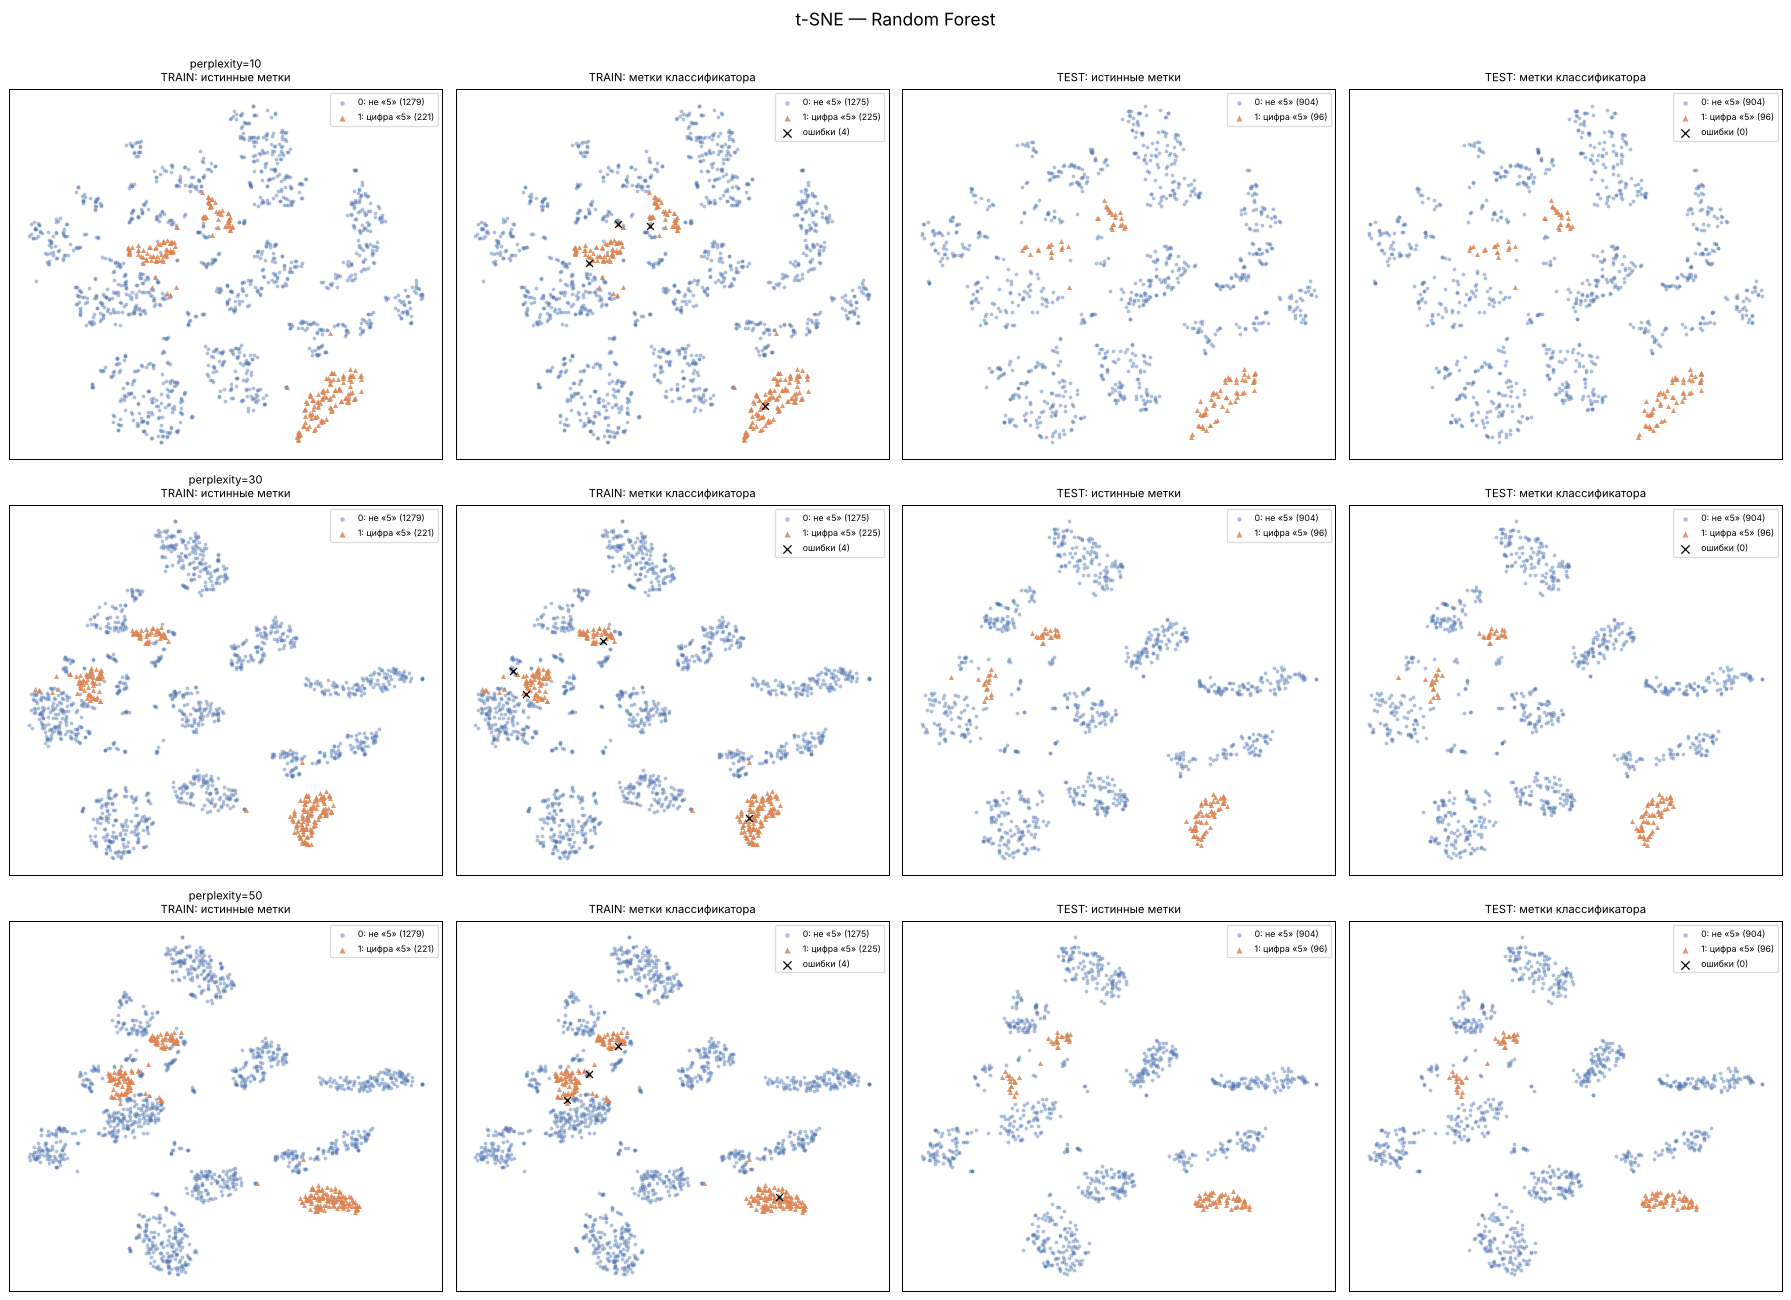

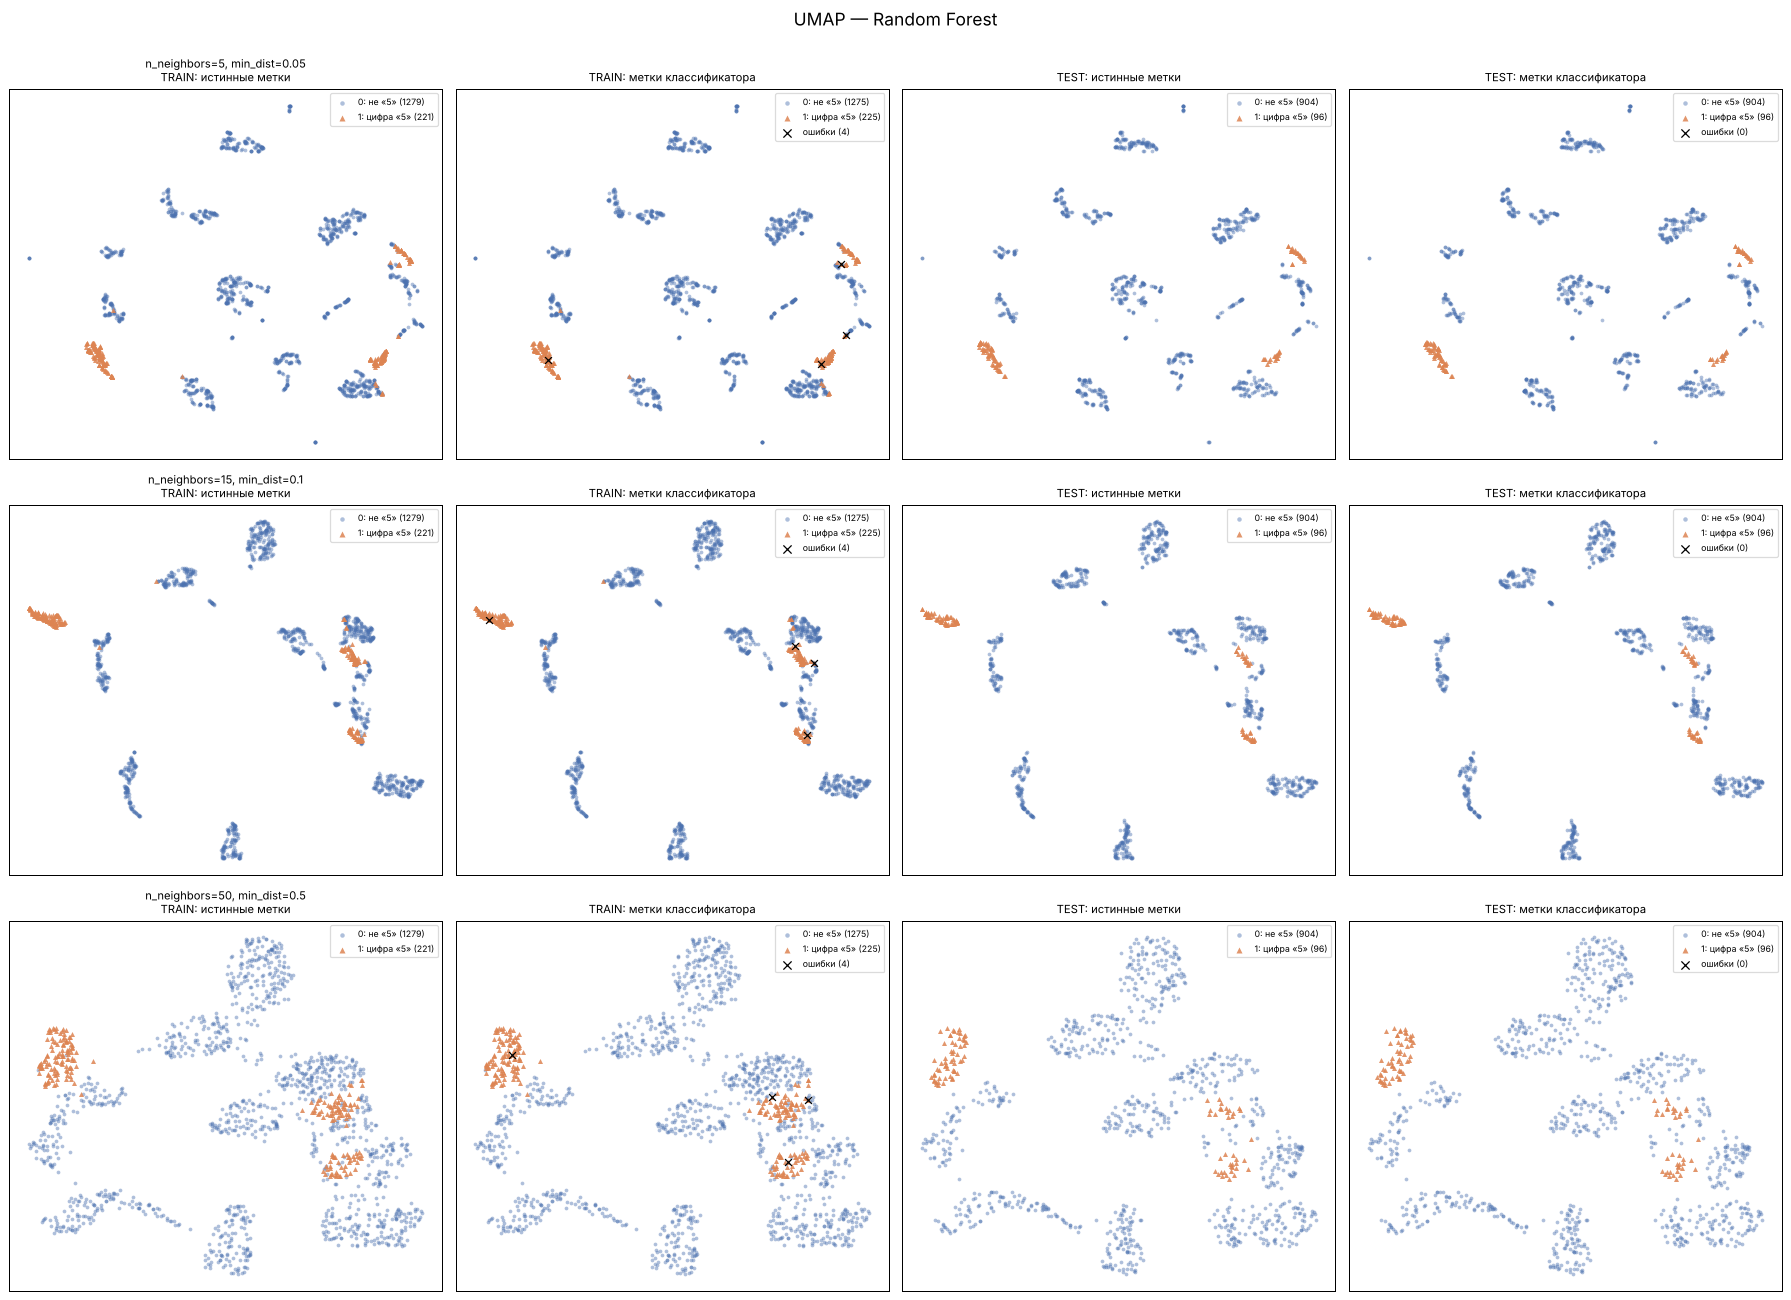

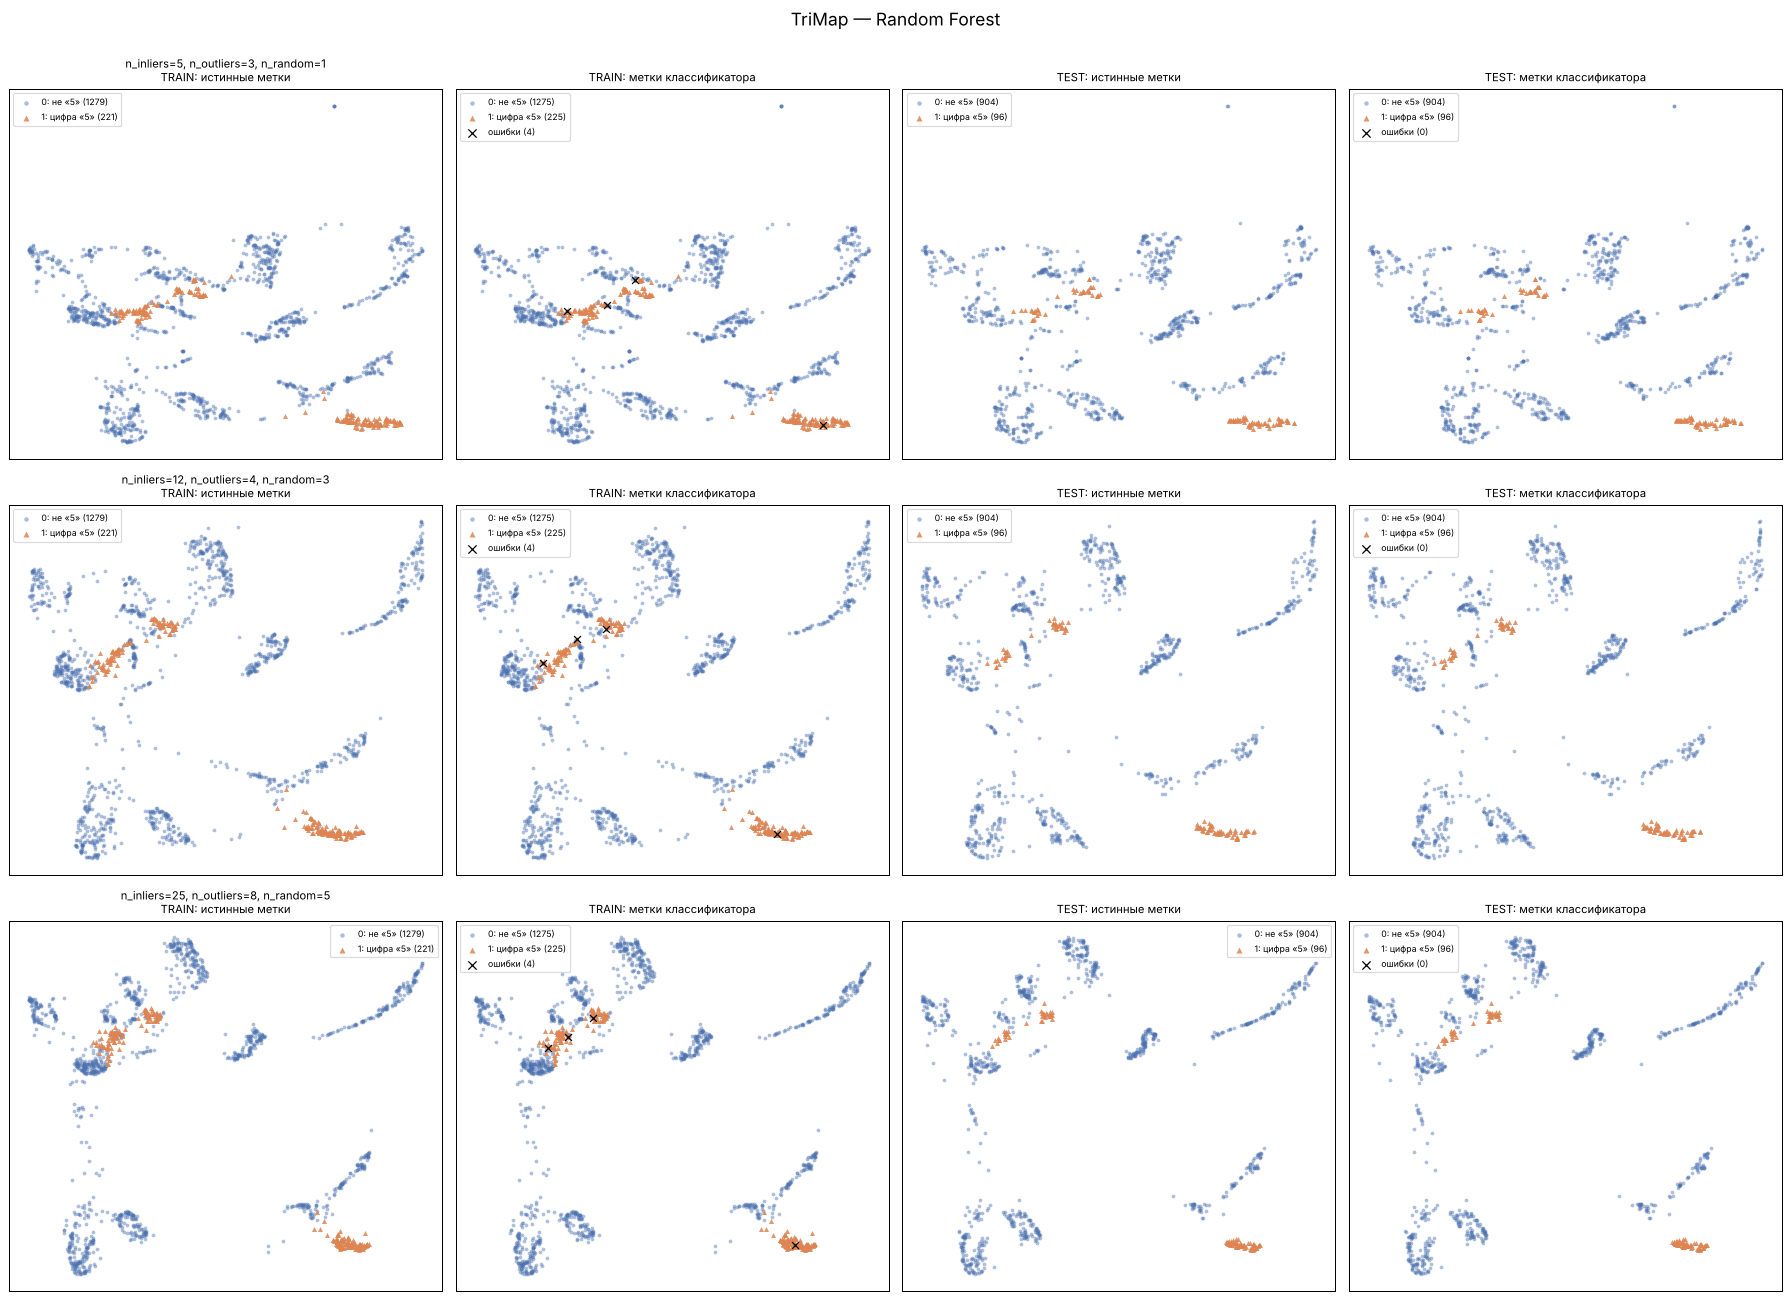

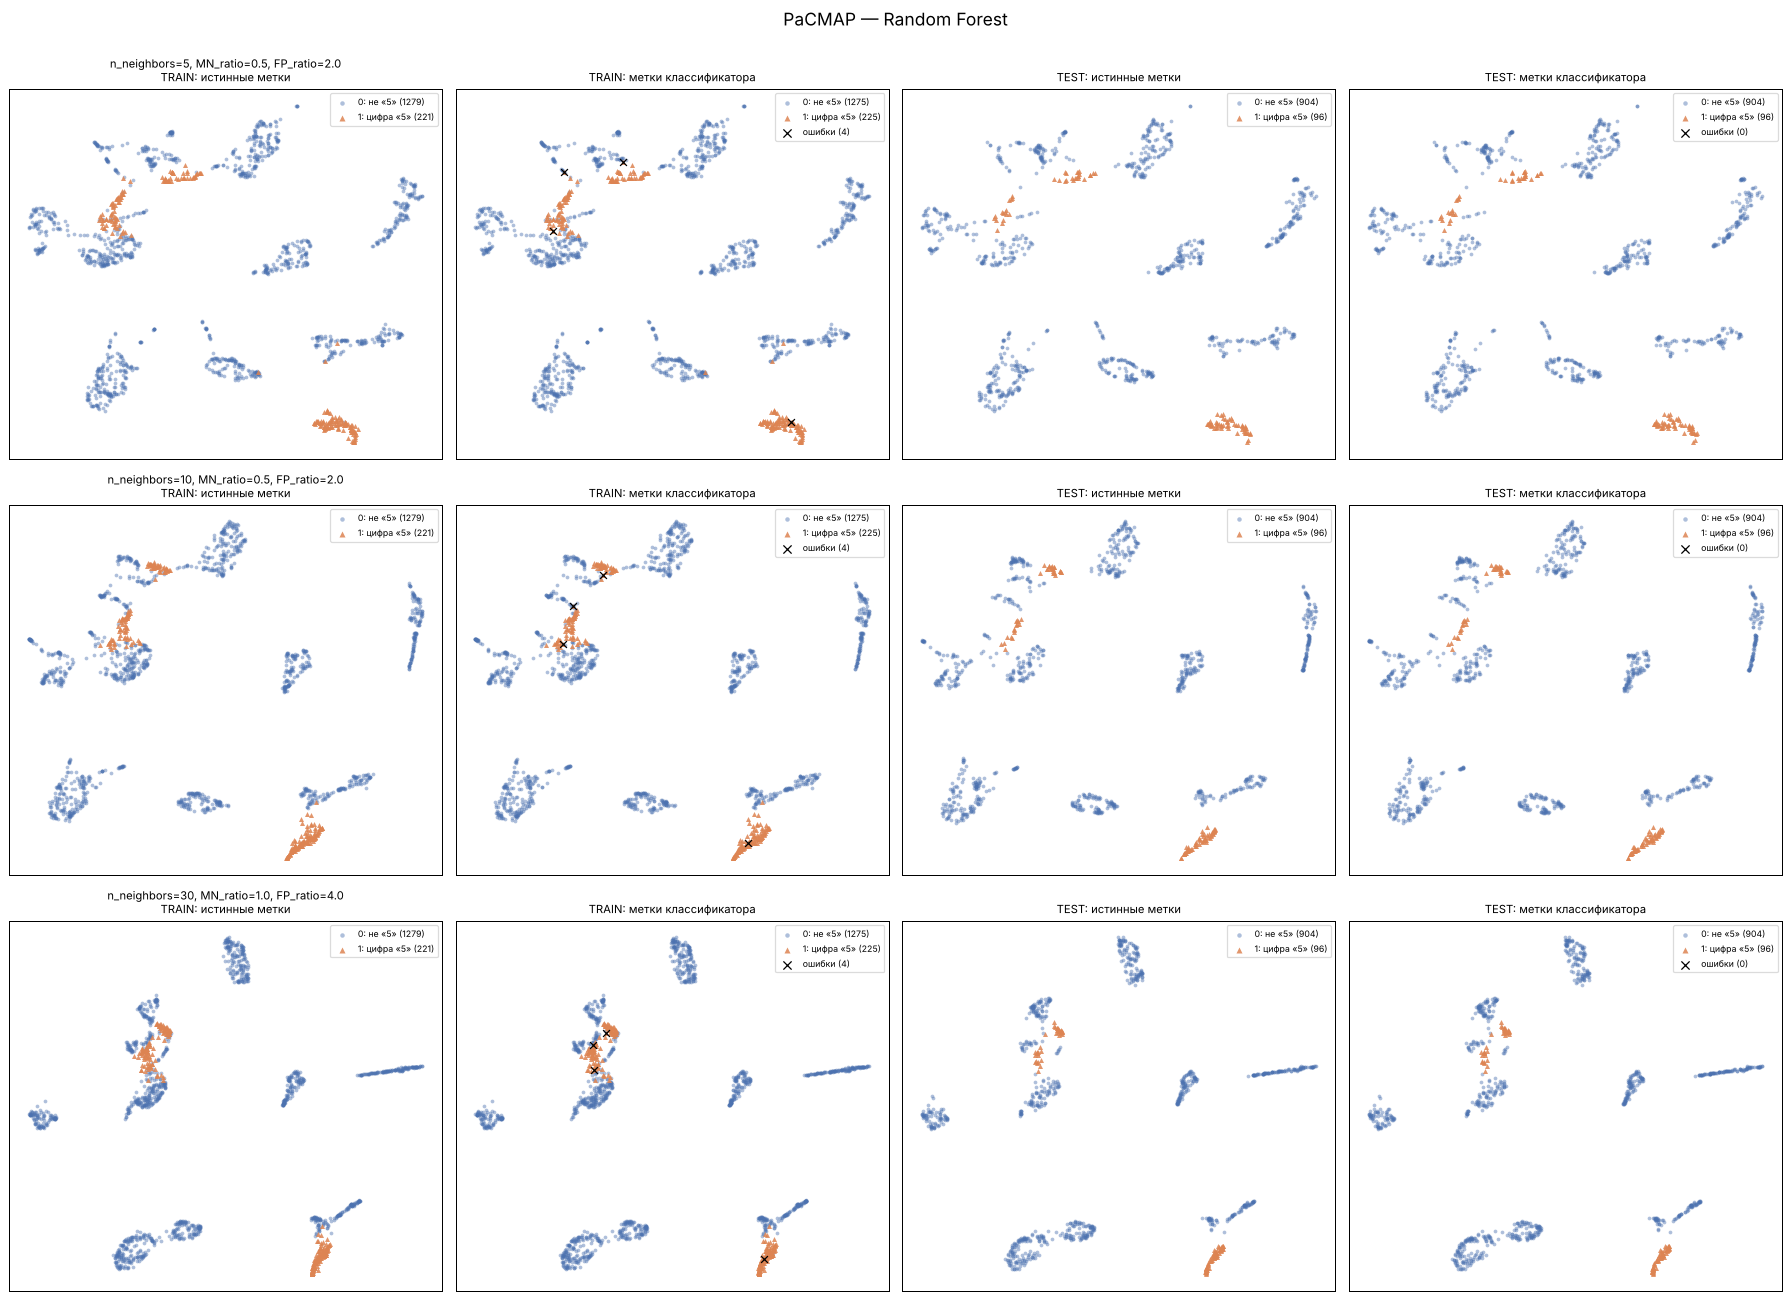

In [25]:
y_pred_viz_rf = best_rf.predict(X_viz)
plot_embeddings(EMBS, y_pred_viz_rf, 'Random Forest')

**Выводы по RF:**
* Лучшая конфигурация: `entropy`, `max_features=0.5`, `max_depth=12`, `min_samples_leaf=4`, `class_weight='balanced_subsample'`, 150 деревьев (CV F1 ≈ 0.98).
* По диаграммам размаха сильнее всего на F1 влияют `class_weight='balanced_subsample'` (повышает recall редкого класса) и критерий `entropy`. Чуть меньше влияет `max_features=0.5`. Число деревьев (50 или 150) и ограничение глубины почти ничего не меняют: лес уже насыщается.
* На train RF показывает ≈ 1.0, OOB accuracy ≈ 0.996, на test F1 ≈ 0.99 (precision = 1.0, recall ≈ 0.98). Лес немного уступает SVM и kNN: несколько «пятёрок» он пропускает.
* Правила голосования: жёсткое голосование на test дало чуть больший recall, чем мягкое. Снижение порога мягкого голосования до 0.3 ещё увеличивает recall «5», но уменьшает precision.
* Самые важные признаки — **конечные точки траектории** (`x8`, `y7`, `y8`) и `x4`. «5» обычно заканчивается внизу слева, после нижней дуги, и этим отличается от большинства других цифр.

### C.2. Визуализация двух деревьев случайного леса

Деревья в лесу обычно очень глубокие, поэтому полностью рисовать их бессмысленно. Показываем **первые 3 уровня** каждого дерева (`max_depth=3` в `plot_tree`), остальное выводим текстом.

**Что записано в узле:**
1. **Условие разбиения** `признак <= порог` (например, `y5 <= 38.5`). Объекты, для которых оно истинно, идут в **левую** ветвь, остальные — в правую. В листьях условия нет.
2. **`gini` / `entropy`** — неоднородность узла по выбранному критерию. 0 означает, что в узле объекты одного класса; максимум для двух классов равен 0.5 (gini) или 1 (entropy).
3. **`samples`** — число *различных* объектов обучающей выборки, попавших в узел. Каждое дерево обучается на бутстрэп-выборке: из N объектов берутся N с возвращением, уникальных среди них ≈ 63 %. Поэтому `samples` в корне меньше размера train.
4. **`value`** — взвешенное количество объектов `[класс 0, класс 1]` в узле. Учитываются кратность бутстрэп-повторов и веса классов. При `class_weight='balanced_subsample'` в корне оба класса уравнены (например, `[4122, 4122]`), а сумма равна размеру train. В некоторых версиях sklearn вместо количеств выводятся доли классов.
5. **`class`** — класс с наибольшим `value`, то есть ответ дерева, если бы узел был листом. Цвет узла показывает класс (оранжевый — 0, синий — 1), насыщенность — чистоту узла. В корне классы уравнены, поэтому `class` там выбран условно.

Деревья в лесу различаются по двум причинам: разные бутстрэп-выборки и случайный набор из `max_features` признаков при каждом разбиении. Поэтому у разных деревьев могут отличаться даже корневые разбиения.

Дерево #0: глубина = 11, листьев = 61, узлов = 121, объектов в корне (samples) = 5226 из 8244, взвешенно = 8244


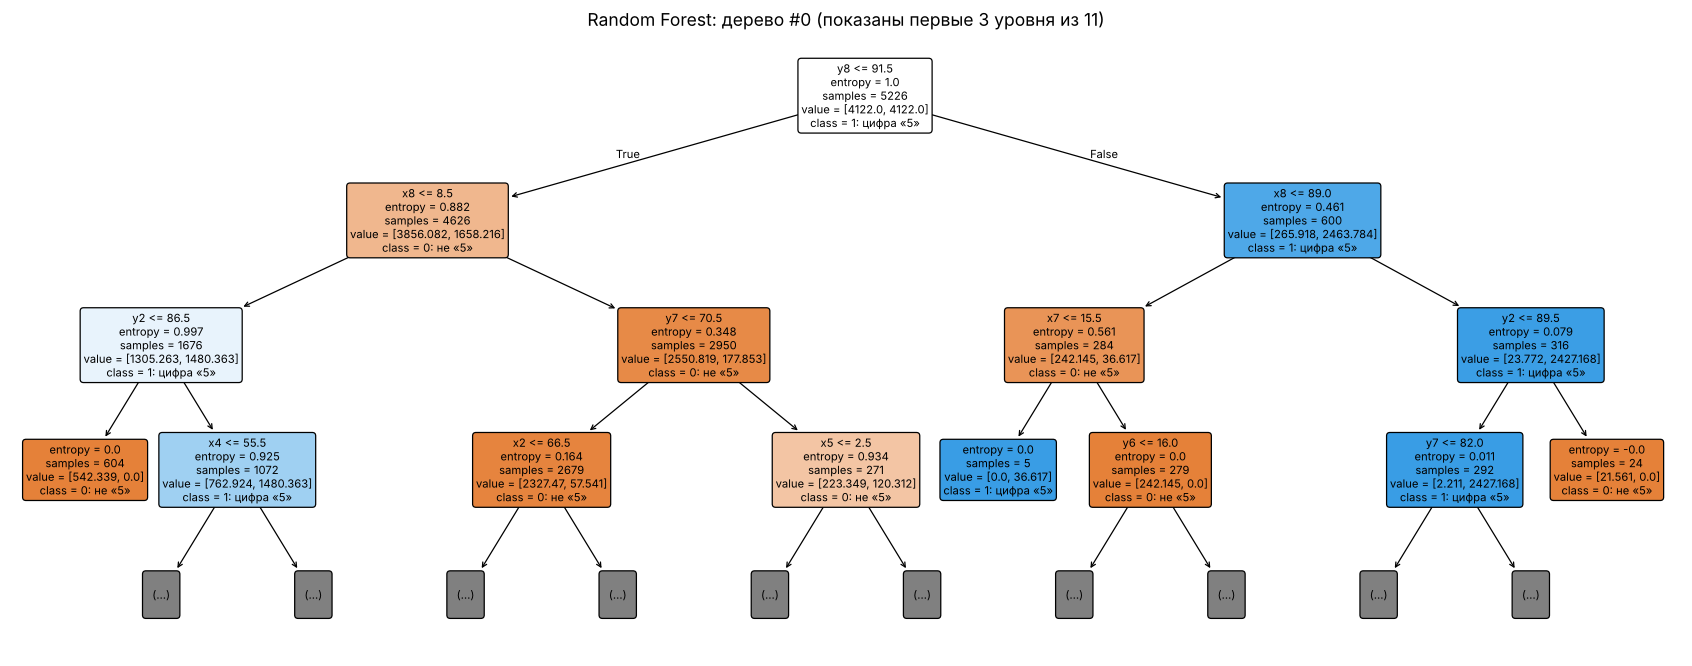

Дерево #1: глубина = 10, листьев = 67, узлов = 133, объектов в корне (samples) = 5205 из 8244, взвешенно = 8244


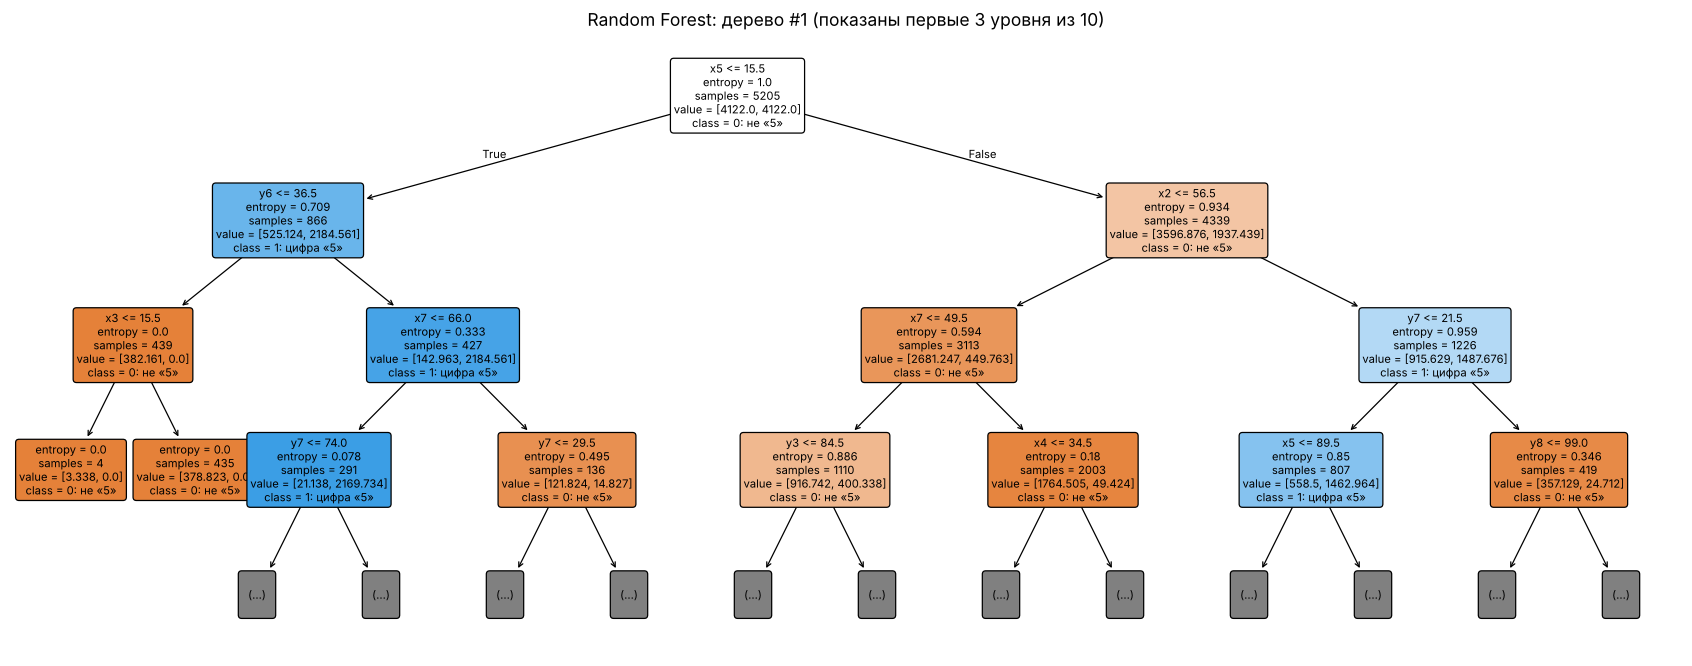

In [26]:
for t_idx in [0, 1]:
    tree = best_rf.estimators_[t_idx]
    print(f'Дерево #{t_idx}: глубина = {tree.get_depth()}, листьев = {tree.get_n_leaves()}, '
          f'узлов = {tree.tree_.node_count}, объектов в корне (samples) = {tree.tree_.n_node_samples[0]} '
          f'из {len(X_train)}, взвешенно = {tree.tree_.weighted_n_node_samples[0]:.0f}')
    fig, ax = plt.subplots(figsize=(24, 9))
    plot_tree(tree, max_depth=3, feature_names=FEATURE_NAMES, class_names=CLASS_NAMES,
              filled=True, rounded=True, impurity=True, proportion=False, precision=3, fontsize=9, ax=ax)
    ax.set_title(f'Random Forest: дерево #{t_idx} (показаны первые 3 уровня из {tree.get_depth()})', fontsize=14)
    plt.show()

In [27]:
for t_idx in [0, 1]:
    print(f'===== Дерево #{t_idx}: первые 4 уровня (weights — взвешенные количества объектов [кл.0, кл.1]) =====')
    print(export_text(best_rf.estimators_[t_idx], feature_names=FEATURE_NAMES, max_depth=4,
                      show_weights=True, decimals=1))

===== Дерево #0: первые 4 уровня (weights — взвешенные количества объектов [кл.0, кл.1]) =====
|--- y8 <= 91.5
|   |--- x8 <= 8.5
|   |   |--- y2 <= 86.5
|   |   |   |--- weights: [542.3, 0.0] class: 0.0
|   |   |--- y2 >  86.5
|   |   |   |--- x4 <= 55.5
|   |   |   |   |--- y7 <= 21.5
|   |   |   |   |   |--- truncated branch of depth 7
|   |   |   |   |--- y7 >  21.5
|   |   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- x4 >  55.5
|   |   |   |   |--- x2 <= 57.5
|   |   |   |   |   |--- weights: [238.8, 0.0] class: 0.0
|   |   |   |   |--- x2 >  57.5
|   |   |   |   |   |--- truncated branch of depth 7
|   |--- x8 >  8.5
|   |   |--- y7 <= 70.5
|   |   |   |--- x2 <= 66.5
|   |   |   |   |--- x8 <= 17.5
|   |   |   |   |   |--- truncated branch of depth 4
|   |   |   |   |--- x8 >  17.5
|   |   |   |   |   |--- weights: [1905.1, 0.0] class: 0.0
|   |   |   |--- x2 >  66.5
|   |   |   |   |--- x8 <= 21.5
|   |   |   |   |   |--- truncated branch of depth 4
|   |   |  

In [28]:
# Путь одного тестового объекта (класса 1) через оба дерева
i = np.where(y_test == 1)[0][0]
x = X_test[i:i + 1]
print(f'Тестовый объект #{i}, истинный класс = {y_test[i]}')
for t_idx in [0, 1]:
    tree = best_rf.estimators_[t_idx]; tr = tree.tree_
    path = tree.decision_path(x).indices
    print(f'\nДерево #{t_idx}:')
    for node in path:
        if tr.children_left[node] == -1:
            frac = tr.value[node][0]
            print(f'  лист {node}: samples={tr.n_node_samples[node]}, value={np.round(frac, 3)} '
                  f'-> голос дерева: класс {np.argmax(frac)} (P(кл.1)={frac[1] / frac.sum():.3f})')
        else:
            f, thr = tr.feature[node], tr.threshold[node]
            go = 'влево' if x[0, f] <= thr else 'вправо'
            print(f'  узел {node}: {FEATURE_NAMES[f]} = {x[0, f]:.1f} <= {thr:.2f}? -> {go}  '
                  f'({best_rf.criterion}={tr.impurity[node]:.3f}, samples={tr.n_node_samples[node]})')
print(f'\nИтог леса: P(кл.1) = {best_rf.predict_proba(x)[0, 1]:.3f} (среднее по {len(best_rf.estimators_)} деревьям), '
      f'предсказание = {best_rf.predict(x)[0]}')

Тестовый объект #20, истинный класс = 1

Дерево #0:
  узел 0: y8 = 0.0 <= 91.50? -> влево  (entropy=1.000, samples=5226)
  узел 1: x8 = 14.0 <= 8.50? -> вправо  (entropy=0.882, samples=4626)
  узел 75: y7 = 9.0 <= 70.50? -> влево  (entropy=0.348, samples=2950)
  узел 76: x2 = 68.0 <= 66.50? -> вправо  (entropy=0.164, samples=2679)
  узел 86: x8 = 14.0 <= 21.50? -> влево  (entropy=0.605, samples=331)
  узел 87: y3 = 89.0 <= 92.50? -> влево  (entropy=0.984, samples=45)
  лист 88: samples=24, value=[1. 0.] -> голос дерева: класс 0 (P(кл.1)=0.000)

Дерево #1:
  узел 0: x5 = 49.0 <= 15.50? -> вправо  (entropy=1.000, samples=5205)
  узел 28: x2 = 68.0 <= 56.50? -> вправо  (entropy=0.934, samples=4339)
  узел 78: y7 = 9.0 <= 21.50? -> влево  (entropy=0.959, samples=1226)
  узел 79: x5 = 49.0 <= 89.50? -> влево  (entropy=0.850, samples=807)
  узел 80: y1 = 89.0 <= 75.50? -> вправо  (entropy=0.704, samples=537)
  узел 82: y3 = 89.0 <= 88.50? -> вправо  (entropy=0.575, samples=412)
  узел 98: y2

---
# Итоговое сравнение лучших классификаторов

accuracy  precision  recall      f1
model         sample                                     
SVM (rbf)     train     0.9989     0.9962  0.9924  0.9943
              test      1.0000     1.0000  1.0000  1.0000
kNN           train     1.0000     1.0000  1.0000  1.0000
              test      1.0000     1.0000  1.0000  1.0000
Random Forest train     0.9995     0.9950  1.0000  0.9975
              test      0.9982     1.0000  0.9811  0.9904

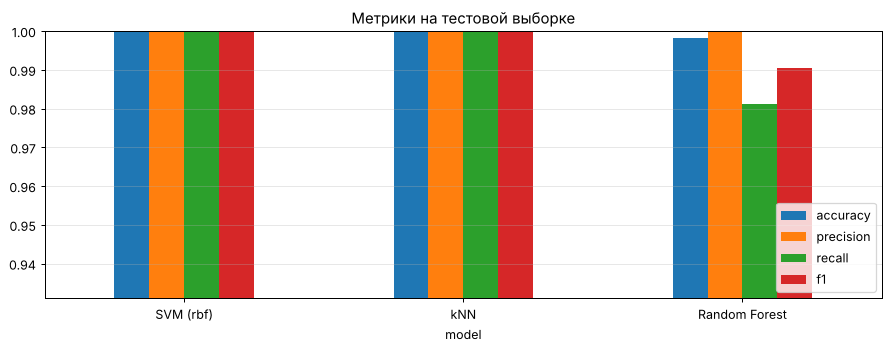

Лучшие гиперпараметры:
  SVM: {'svc__C': 1, 'svc__class_weight': None, 'svc__gamma': 0.1, 'svc__kernel': 'rbf'}
  kNN: {'knn__metric': 'cosine', 'knn__n_neighbors': 1, 'knn__weights': 'uniform'}
  RF : {'class_weight': 'balanced_subsample', 'criterion': 'entropy', 'max_depth': 12, 'max_features': 0.5, 'min_samples_leaf': 4, 'n_estimators': 150}


In [29]:
summary = pd.concat([evaluate(best_svm, f'SVM ({best_kernel})'), evaluate(best_knn, 'kNN'),
                     evaluate(best_rf, 'Random Forest')])
display(summary)

test_only = summary.xs('test', level='sample')
test_only.plot.bar(figsize=(10, 4), rot=0, ylim=(max(0, test_only.values.min() - 0.05), 1.0),
                   title='Метрики на тестовой выборке')
plt.legend(loc='lower right'); plt.grid(axis='y', alpha=.3); plt.tight_layout(); plt.show()

print('Лучшие гиперпараметры:')
print('  SVM:', svm_gs.best_params_)
print('  kNN:', knn_gs.best_params_)
print('  RF :', rf_gs.best_params_)

**Общие выводы**
1. Набор `pen_digits` (цифра «5» против остальных) несбалансирован (9.4 : 1), поэтому accuracy высока даже у тривиальной модели. Модели сравнивались по **F1, precision и recall для редкого класса**.
2. **SVM с RBF-ядром** (`C=1`, `gamma=0.1`) — лучший SVM. На test F1 = 1.0, опорных векторов около 3 % train. Полиномиальное ядро почти так же точно, линейное и сигмоидное заметно хуже (F1 ≈ 0.80 и ≈ 0.68).
3. **kNN** (k=1, косинусная метрика) на масштабированных признаках работает на уровне SVM (F1 на test = 1.0): в 16-мерном пространстве классы разделены локально.
4. **Random Forest** немного уступает (F1 ≈ 0.99) за счёт recall редкого класса. Отчасти это исправляется весами классов (`balanced_subsample`), жёстким голосованием или снижением порога мягкого голосования.
5. t-SNE, UMAP, TriMap и PaCMAP показывают, что класс «5» образует несколько компактных кластеров, а опорные векторы SVM и ошибки моделей сосредоточены на их границах.

*(Конкретные числа берите из таблиц выше: они зависят от разбиения и версий библиотек. Если формулировки выводов разойдутся с вашими результатами, поправьте текст.)*